# Clase completa de NLP: EDA, limpieza y análisis de sentimiento con Logistic Regression

**Dataset:** `imdb_movie_reviews_large.csv`  
**Problema:** clasificación binaria de sentimiento en reseñas de películas.  
**Modelo único:** Logistic Regression.  
**Representaciones:** One-Hot / Binary Encoding, Bag of Words y TF-IDF.

---

## Objetivos de aprendizaje

Al finalizar este notebook, el estudiante estará en capacidad de:

1. Explorar visualmente un dataset textual.
2. Identificar problemas comunes en datos de texto: ruido, stop words, palabras raras, HTML, signos, longitud variable.
3. Construir una función de normalización y limpieza de texto.
4. Transformar texto en vectores usando representaciones clásicas.
5. Entrenar modelos de clasificación de sentimiento usando Logistic Regression.
6. Evaluar modelos con métricas de clasificación.
7. Comparar el impacto de diferentes representaciones y de la limpieza textual.
8. Interpretar errores y palabras importantes del modelo.

---

## Estructura del notebook

0. Configuración inicial  
1. NLP EDA  
2. Text Normalizing and Cleaning  
3. Sentiment Analysis con One-Hot / Binary Encoding  
4. Sentiment Analysis con Bag of Words  
5. Sentiment Analysis con TF-IDF  
6. Comparación global de resultados  
7. Interpretación del modelo  
8. Análisis de errores  
9. Conclusiones

> **Versión para estudiantes (sin soluciones):** las celdas marcadas `TODO` son actividades para completar en clase. Las celdas de código no incluyen resultados precalculados. Ejecute las celdas progresivamente; los bloques con `NotImplementedError` requieren implementación antes de continuar.


# 0. Configuración inicial

En esta sección preparamos las importaciones y completaremos en clase la carga del dataset y las funciones auxiliares.

En un proyecto real de NLP, esta etapa es importante porque permite que todo el pipeline sea reproducible.  
Un pipeline reproducible debe dejar claro:

- Qué datos se usan.
- Qué columnas contienen el texto y la etiqueta.
- Cómo se divide el dataset en entrenamiento y prueba.
- Qué semilla aleatoria se usa.
- Qué métricas se van a reportar.

In [383]:
# ============================================================
# 0.1 Imports generales
# ============================================================

import os
import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from wordcloud import WordCloud
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 160)

In [384]:
# TODO: Defina DATA_PATH con la ruta del CSV que se usará en clase.
# Pista: confirme el nombre real del archivo antes de leerlo.
DATA_PATH = "imdb_movie_reviews_large.csv"  # Reemplace con la ruta correcta del archivo CSV
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"No se encontró '{DATA_PATH}'. "
        "Coloque el archivo en la misma carpeta del notebook."
    )

In [385]:
# TODO: Cargue el archivo CSV en un DataFrame llamado df usando pandas.
df = pd.read_csv(DATA_PATH)

In [386]:
# TODO: Muestre las primeras 10 filas del dataset.
df.head(10)

,review,sentiment
0,Stunning coordination and compelling dialogue. The movie kept me engaged from start to finish.,1
1,Boring and predictable. Not worth watching. The movie disappointed me and the {element} was completely obvious.,0
2,Incredible production design and engaging narrative. The movie kept me on the edge of my seat throughout.,1
3,Exceptional work of art. The movie touched my heart and left me thinking about it for days.,1
4,Atrocious {element} and deplorable {aspect}. This is a turkey that fails on every level.,0
5,Terrible waste of two hours. The {element} was inferior and the {element} was painful to listen to.,0
6,Outstanding character development and brilliant screenplay. This is how movies should be made.,1
7,Disappointing and overlong. The movie had some {positive_element} but overall it was a letdown.,0
8,Brilliant screenplay with exceptional acting. This is platinum at its finest.,1
9,Fantastic storyline and wonderful dialogue. The movie was a platinum that exceeded all expectations.,1


In [387]:
# ============================================================
# 0.3 Inspección inicial
# ============================================================

# TODO:
# - Imprima las columnas.
# - Revise los tipos de datos.
# - Revise valores nulos.
# - Revise la distribución de la variable objetivo.

print("Columnas:") 
print(df.columns)

print("Tipos de datos:") 
print(df.dtypes)

print("Valores nulos:") 
print(df.isnull().sum())

print("Distribución de la variable objetivo:") 
print(df['sentiment'].value_counts())

Columnas:
Index(['review', 'sentiment'], dtype='str')
Tipos de datos:
review         str
sentiment    int64
dtype: object
Valores nulos:
review       0
sentiment    0
dtype: int64
Distribución de la variable objetivo:
sentiment
1    1000
0    1000
Name: count, dtype: int64


## 0.4 Definición de columnas

Este dataset tiene:

- `review`: texto de la reseña.
- `sentiment`: etiqueta de sentimiento.
    - `1`: sentimiento positivo.
    - `0`: sentimiento negativo.

Vamos a crear variables estándar para que el resto del notebook sea más fácil de reutilizar.

In [388]:
# TODO: Identifique y defina TEXT_COL y LABEL_COL según el archivo.
# TODO: Cree la columna sentiment_label con etiquetas consistentes.
TEXT_COL = "review"  # columna con el texto de la reseña
LABEL_COL = "sentiment"  # columna con la etiqueta (1 = positivo, 0 = negativo)

#Validación de columnas requeridas
required_columns = {TEXT_COL, LABEL_COL}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Faltan columnas requeridas: {missing_columns}")

# Mapeo de etiquetas a nombres legibles
df["sentiment_label"] = df[LABEL_COL].map({1: "positive", 0: "negative", "0": "negative", "1": "positive"})
df[[TEXT_COL, LABEL_COL, "sentiment_label"]].head()

,review,sentiment,sentiment_label
0,Stunning coordination and compelling dialogue. The movie kept me engaged from start to finish.,1,positive
1,Boring and predictable. Not worth watching. The movie disappointed me and the {element} was completely obvious.,0,negative
2,Incredible production design and engaging narrative. The movie kept me on the edge of my seat throughout.,1,positive
3,Exceptional work of art. The movie touched my heart and left me thinking about it for days.,1,positive
4,Atrocious {element} and deplorable {aspect}. This is a turkey that fails on every level.,0,negative


## 0.5 Calidad de datos: duplicados y plantillas sin rellenar

Antes de explorar conviene revisar dos problemas que afectan la evaluación:

- **Reseñas duplicadas:** si el mismo texto queda en entrenamiento y en prueba, el modelo se evalúa con ejemplos que ya vio.
- **Plantillas sin rellenar**, como `{element}` o `{aspect}`: indican que el dataset fue generado de forma automática.

In [389]:
# Reseñas repetidas (mismo texto exacto)
duplicadas = df.duplicated(subset=[TEXT_COL])
print(f"Reseñas en el archivo: {len(df)}")
print(f"Reseñas duplicadas: {duplicadas.sum()} ({duplicadas.mean():.1%})")
print("Duplicadas por clase:", df.loc[duplicadas, "sentiment_label"].value_counts().to_dict())
print("Textos con etiquetas contradictorias:", int((df.groupby(TEXT_COL)[LABEL_COL].nunique() > 1).sum()))

# Plantillas sin rellenar
df["tiene_plantilla"] = df[TEXT_COL].str.contains(r"\{\w+\}")
print("\nReseñas con plantilla, por clase:")
display(pd.crosstab(df["sentiment_label"], df["tiene_plantilla"]))

Reseñas en el archivo: 2000
Reseñas duplicadas: 809 (40.5%)
Duplicadas por clase: {'negative': 612, 'positive': 197}
Textos con etiquetas contradictorias: 0

Reseñas con plantilla, por clase:


tiene_plantilla,False,True
sentiment_label,,
negative,63,937
positive,1000,0


### Decisión: eliminar duplicados antes de explorar y dividir

Se sigue el criterio del notebook de clase: las reseñas repetidas pueden quedar a la vez en entrenamiento y en prueba y dar una evaluación demasiado optimista. Como ningún texto tiene etiquetas contradictorias, basta con conservar la primera aparición de cada reseña. Todo el análisis que sigue usa las reseñas únicas; el archivo completo se guarda en `df_full` solo para comparar.

In [390]:
df_full = df.copy()                        # archivo completo, solo para comparaciones
df = df.drop_duplicates(subset=[TEXT_COL])  # conserva la primera aparición y el índice original
print(f"Reseñas antes: {len(df_full)} | después: {len(df)} | eliminadas: {len(df_full) - len(df)}")

balance = df["sentiment_label"].value_counts()
display(pd.DataFrame({"reseñas": balance, "proporción": (balance / balance.sum()).round(3)}))

# Dos líneas base para comparar con los modelos
regla_plantilla = (~df["tiene_plantilla"]).astype(int)  # "si tiene plantilla, es negativa"
print(f"Accuracy de predecir siempre 'positiva': {(df[LABEL_COL] == 1).mean():.3f}")
print(f"Accuracy de la regla 'si tiene plantilla, es negativa': {accuracy_score(df[LABEL_COL], regla_plantilla):.3f}")

Reseñas antes: 2000 | después: 1191 | eliminadas: 809


,reseñas,proporción
sentiment_label,,
positive,803,0.674
negative,388,0.326


Accuracy de predecir siempre 'positiva': 0.674
Accuracy de la regla 'si tiene plantilla, es negativa': 0.983


## Ejercicio 0

Responda brevemente:

1. ¿Cuántas reseñas tiene el dataset?

   **Respuesta:** El archivo trae 2.000 reseñas sin valores nulos, pero 809 (40,5 %) son copias exactas de otras. Al quitarlas quedan 1.191 reseñas únicas, que son las que uso en el resto del análisis.

In [391]:
# Pregunta 1: número de reseñas
print("Reseñas en el archivo:", len(df_full))
print("Reseñas únicas (sin duplicados):", len(df))
print("Valores nulos:", df[[TEXT_COL, LABEL_COL]].isnull().sum().sum())

Reseñas en el archivo: 2000
Reseñas únicas (sin duplicados): 1191
Valores nulos: 0


2. ¿Cuántas clases tiene el problema?

   **Respuesta:** Dos: positivo (1) y negativo (0). Es una clasificación binaria.

In [392]:
# Pregunta 2: número de clases
print("Número de clases:", df[LABEL_COL].nunique())
print("Clases:", sorted(df[LABEL_COL].unique().tolist()))

Número de clases: 2
Clases: [0, 1]


3. ¿El dataset está balanceado?

   **Respuesta:** El archivo sí (1.000 y 1.000), pero es un balance aparente: la mayoría de las copias son negativas (612 de 809). Sin duplicados quedan 803 positivas (67,4 %) y 388 negativas (32,6 %), es decir, un desbalance moderado.

In [393]:
# Pregunta 3: balance de clases
# TODO: Calcule cuántas observaciones hay por clase.
conteo = pd.DataFrame({
    "archivo": df_full[LABEL_COL].value_counts(),
    "sin_duplicados": df[LABEL_COL].value_counts(),
})
conteo["pct_sin_duplicados"] = (conteo["sin_duplicados"] / conteo["sin_duplicados"].sum() * 100).round(1)
conteo

,archivo,sin_duplicados,pct_sin_duplicados
sentiment,,,
1,1000,803,67.4
0,1000,388,32.6


4. ¿Qué podría pasar si el dataset estuviera muy desbalanceado?

   **Respuesta:** El modelo se inclinaría por la clase mayoritaria y el accuracy dejaría de ser confiable. Aquí ya se nota: responder siempre "positivo" da 67,4 % de accuracy sin detectar ni una negativa, y con 95 % de positivas llegaría a 95 %. Por eso divido con `stratify` y miro F1, recall y ROC-AUC, no solo el accuracy.

In [394]:
# Pregunta 4: qué pasa con un modelo que siempre predice la clase mayoritaria
# a) En este dataset, ya sin duplicados
y_real = df[LABEL_COL].values
y_siempre_pos = np.ones_like(y_real)
print("Dataset sin duplicados -> accuracy:", round(accuracy_score(y_real, y_siempre_pos), 3),
      "| recall de la clase negativa:", recall_score(y_real, y_siempre_pos, pos_label=0))

# b) En una simulación muy desbalanceada (95 % positivo / 5 % negativo)
y_true_sim = np.array([1] * 950 + [0] * 50)
y_pred_sim = np.ones_like(y_true_sim)
print("Simulación 95/5        -> accuracy:", accuracy_score(y_true_sim, y_pred_sim),
      "| recall de la clase negativa:", recall_score(y_true_sim, y_pred_sim, pos_label=0))

Dataset sin duplicados -> accuracy: 0.674 | recall de la clase negativa: 0.0
Simulación 95/5        -> accuracy: 0.95 | recall de la clase negativa: 0.0


# 1. NLP EDA

La exploración de datos en NLP no solo busca entender cuántas filas y columnas tenemos.  
En texto, también debemos entender:

- Longitud de los documentos.
- Palabras más frecuentes.
- Palabras poco frecuentes.
- Stop words.
- Diferencias entre clases.
- Ruido textual.
- Patrones visuales.

Esta etapa ayuda a decidir qué limpieza realizar y qué representación textual puede funcionar mejor.

In [395]:
# TODO: Calcule num_chars y num_words por reseña.
# Pista: aplique len y separe el texto en palabras.
df["num_chars"] = df[TEXT_COL].apply(len)
df["num_words"] = df[TEXT_COL].apply(lambda x: len(x.split()))
df[[TEXT_COL, "num_chars", "num_words"]].head()

,review,num_chars,num_words
0,Stunning coordination and compelling dialogue. The movie kept me engaged from start to finish.,94,14
1,Boring and predictable. Not worth watching. The movie disappointed me and the {element} was completely obvious.,111,16
2,Incredible production design and engaging narrative. The movie kept me on the edge of my seat throughout.,105,17
3,Exceptional work of art. The movie touched my heart and left me thinking about it for days.,91,17
4,Atrocious {element} and deplorable {aspect}. This is a turkey that fails on every level.,88,14


In [396]:
# TODO: Muestre estadísticas descriptivas globales y por clase para las longitudes.
display(df[["num_chars", "num_words"]].describe())
display(df.groupby(LABEL_COL)[["num_chars", "num_words"]].describe().T)

,num_chars,num_words
count,1191.000000,1191.000000
mean,99.775819,15.032746
std,12.941210,1.921948
min,72.000000,11.000000
25%,92.000000,14.000000
50%,98.000000,15.000000
75%,107.000000,16.000000
max,143.000000,22.000000


sentiment                 0           1
num_chars count  388.000000  803.000000
          mean    94.652062  102.251557
          std      8.543554   13.944099
          min     72.000000   72.000000
          25%     88.000000   93.000000
          50%     95.000000  101.000000
          75%    101.000000  110.000000
          max    115.000000  143.000000
num_words count  388.000000  803.000000
          mean    14.969072   15.063512
          std      1.594264    2.061934
          min     12.000000   11.000000
          25%     14.000000   14.000000
          50%     15.000000   15.000000
          75%     16.000000   16.000000
          max     18.000000   22.000000

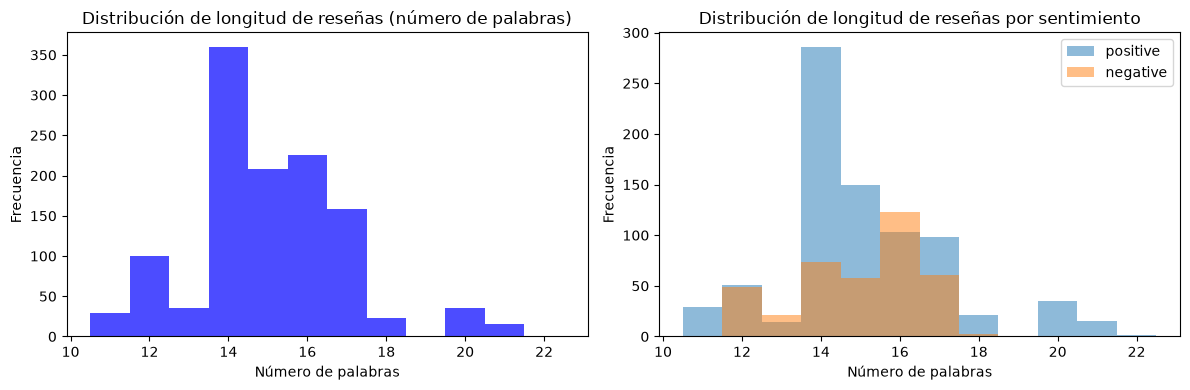

In [397]:
# TODO: Grafique histogramas de longitud de reseñas, global y por sentimiento.

# Una barra por cada número entero de palabras, con los mismos bordes en todos los histogramas.
bins = np.arange(df["num_words"].min(), df["num_words"].max() + 2) - 0.5

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

#Global
axes[0].hist(df["num_words"], bins=bins, color='blue', alpha=0.7)
axes[0].set_title("Distribución de longitud de reseñas (número de palabras)")
axes[0].set_xlabel("Número de palabras")
axes[0].set_ylabel("Frecuencia")

#Por sentimiento
for valor, nombre in [(1, "positive") , (0, "negative")]:
    subset = df[df[LABEL_COL] == valor]
    axes[1].hist(subset["num_words"], bins=bins, alpha=0.5, label=nombre)
axes[1].set_title("Distribución de longitud de reseñas por sentimiento")
axes[1].set_xlabel("Número de palabras")
axes[1].set_ylabel("Frecuencia")
axes[1].legend()

plt.tight_layout()
plt.show()

## 1.1 Palabras frecuentes

Una de las formas más simples de entender un corpus es contar palabras.

Sin embargo, hay que tener cuidado: las palabras más frecuentes suelen ser artículos, preposiciones y conectores.  
Por eso analizaremos:

1. Palabras frecuentes sin remover stop words.
2. Palabras frecuentes removiendo stop words.
3. Palabras frecuentes por clase.

In [398]:
# TODO: Implemente estas tres funciones (no están resueltas):
# - simple_tokenize(text): tokenización simple con re.findall
# - get_top_words(texts, n=20, remove_stopwords=False): contar con Counter
# - plot_top_words(top_words, title): gráfico de barras
# Pista: ENGLISH_STOP_WORDS permite filtrar stop words.

def simple_tokenize(text):
    # TODO: complete la tokenización
    return re.findall(r"[a-z']+", text.lower())

def get_top_words(texts, n=20, remove_stopwords=False):
    # TODO: complete el conteo de palabras
    vocab = Counter()
    for text in texts:
        tokens = simple_tokenize(text)
        if remove_stopwords:
            tokens = [token for token in tokens if token not in ENGLISH_STOP_WORDS]
        vocab.update(tokens)
    return vocab.most_common(n)

def plot_top_words(top_words, title):
    # TODO: complete la visualización
    words, counts = zip(*top_words)
    plt.figure(figsize=(8, 6))
    plt.barh(words, counts)
    plt.gca().invert_yaxis()  # Invertir el eje y para que la palabra más frecuente esté arriba
    plt.title(title)
    plt.xlabel("Frecuencia")
    plt.ylabel("Palabras")
    plt.show()

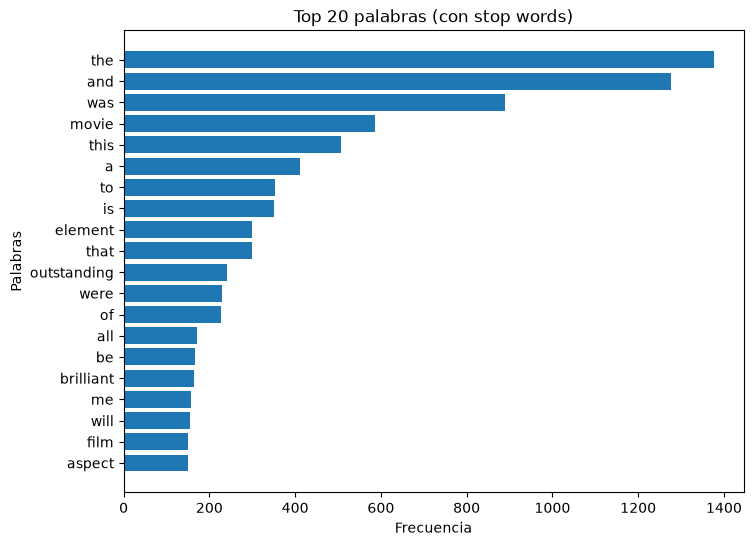

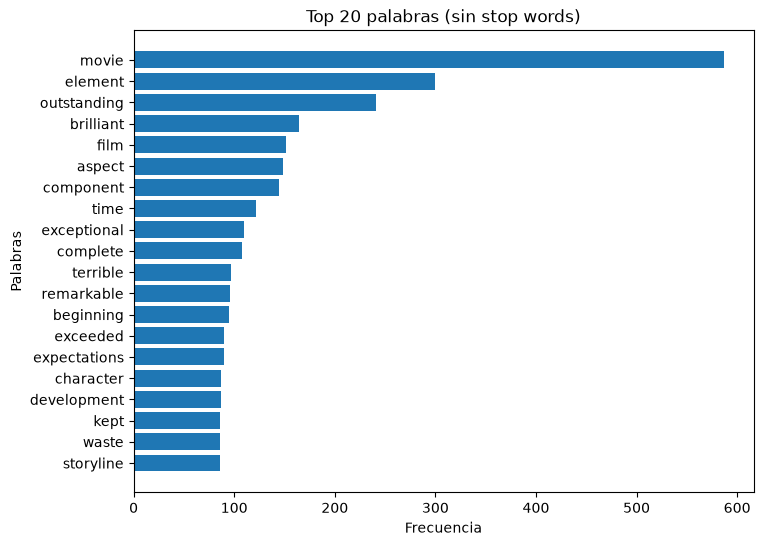

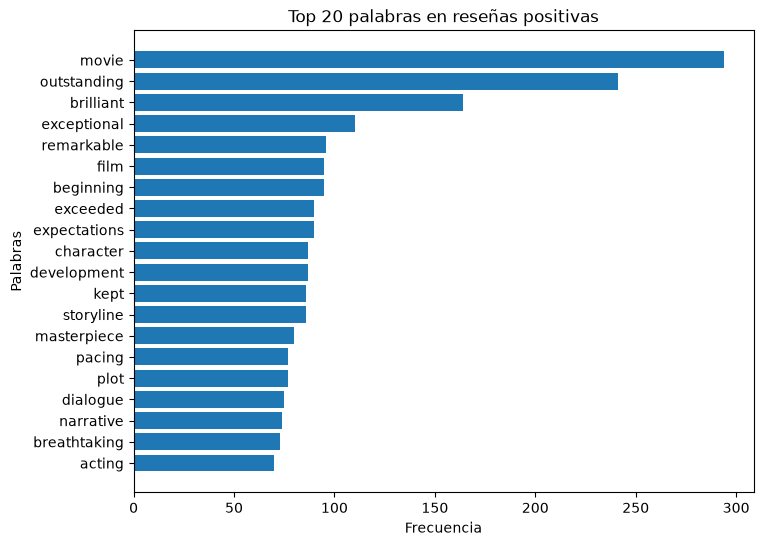

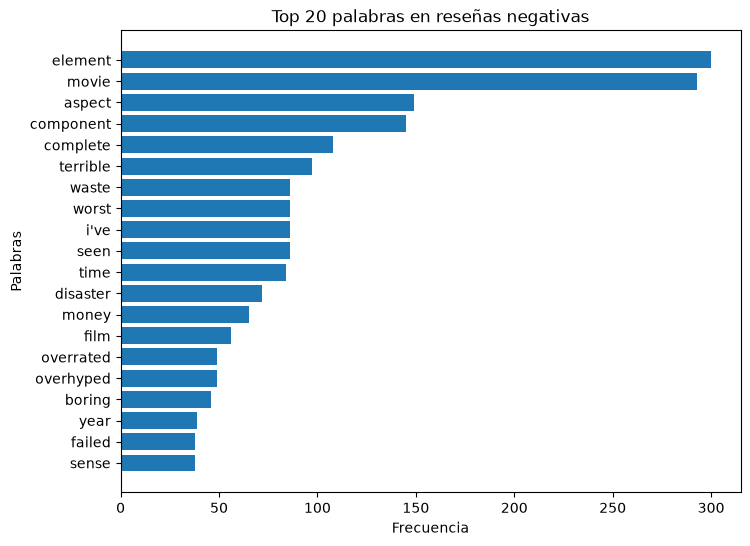

In [399]:
# TODO: Compare palabras frecuentes con/sin stop words y en reviews positivas/negativas.
# Use las funciones que implementó en la celda anterior.

# Corpus completo: con y sin stop words
plot_top_words(get_top_words(df[TEXT_COL], n=20), "Top 20 palabras (con stop words)")
plot_top_words(get_top_words(df[TEXT_COL], n=20, remove_stopwords=True), "Top 20 palabras (sin stop words)")

# Por sentimiento, sin stop words
pos_texts = df[df[LABEL_COL] == 1][TEXT_COL]
neg_texts = df[df[LABEL_COL] == 0][TEXT_COL]

plot_top_words(get_top_words(pos_texts, n=20, remove_stopwords=True), "Top 20 palabras en reseñas positivas")
plot_top_words(get_top_words(neg_texts, n=20, remove_stopwords=True), "Top 20 palabras en reseñas negativas")

## 1.2 Palabras raras

Las palabras raras son términos que aparecen muy pocas veces.  
Pueden ser útiles si representan conceptos específicos, pero también pueden ser ruido:

- Errores de escritura.
- Nombres propios.
- Tokens generados por mala limpieza.
- Símbolos mezclados con texto.
- Palabras demasiado específicas.

En modelos clásicos, un vocabulario muy grande puede hacer que las matrices sean muy dispersas.

In [400]:
# TODO: Construya el vocabulario de todo el corpus.
# Calcule palabras únicas, hapax legomena (frecuencia 1) y ejemplos.
# Pista: Counter.
vocab = Counter()
for text in df[TEXT_COL]:
    vocab.update(simple_tokenize(text))

hapax = [palabra for palabra, freq in vocab.items() if freq == 1]

print("Palabras únicas:", len(vocab))
print("Hapax legomena:", len(hapax))
print("Ejemplos:", hapax[:20])

Palabras únicas: 363
Hapax legomena: 43
Ejemplos: ['disappointed', 'work', 'touched', 'heart', 'left', 'thinking', 'about', 'days', 'overlong', 'some', 'overall', 'letdown', 'avoid', 'costs', "it's", 'deliver', 'promises', 'offered', 'nothing', 'new']


In [401]:
# TODO: Reporte el tamaño del vocabulario, cantidad y porcentaje de palabras raras.
vocab_tamano = len(vocab)
n_raras = len(hapax)
pct_raras = (n_raras / vocab_tamano) * 100

print("Tamaño del vocabulario:", vocab_tamano)
print("Cantidad de palabras raras:", n_raras)
print("Porcentaje de palabras raras:", f"{pct_raras:.2f}%")

Tamaño del vocabulario: 363
Cantidad de palabras raras: 43
Porcentaje de palabras raras: 11.85%


count    1191.000000
mean        0.457035
std         0.064286
min         0.333333
25%         0.411765
50%         0.437500
75%         0.500000
max         0.625000
Name: stopword_ratio, dtype: float64

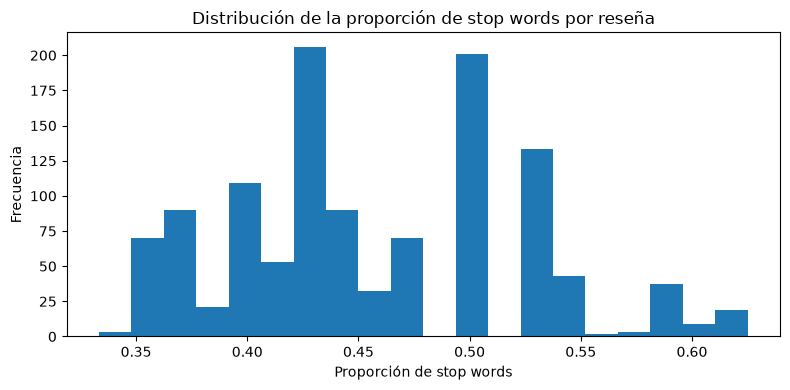

In [402]:
# TODO: Implemente stopword_ratio(text) y visualice su distribución.
# Pista: razón entre cantidad de stop words y total de tokens.
def stopword_ratio(text):
    tokens = simple_tokenize(text)
    if not tokens:  # evita dividir por cero en textos vacíos
        return 0.0
    n_stop = sum(token in ENGLISH_STOP_WORDS for token in tokens)
    return n_stop / len(tokens)

df["stopword_ratio"] = df[TEXT_COL].apply(stopword_ratio)
display(df["stopword_ratio"].describe())

plt.figure(figsize=(8, 4))
plt.hist(df["stopword_ratio"], bins=20)
plt.title("Distribución de la proporción de stop words por reseña")
plt.xlabel("Proporción de stop words")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

## 1.3 Nubes de palabras

Las nubes de palabras son visualizaciones útiles para clase porque muestran de forma intuitiva qué términos dominan en el corpus.

No deben tomarse como una prueba estadística fuerte, pero ayudan a generar hipótesis.

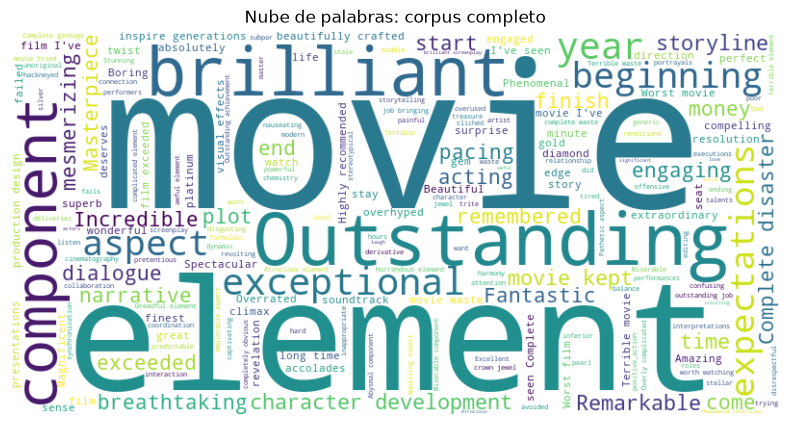

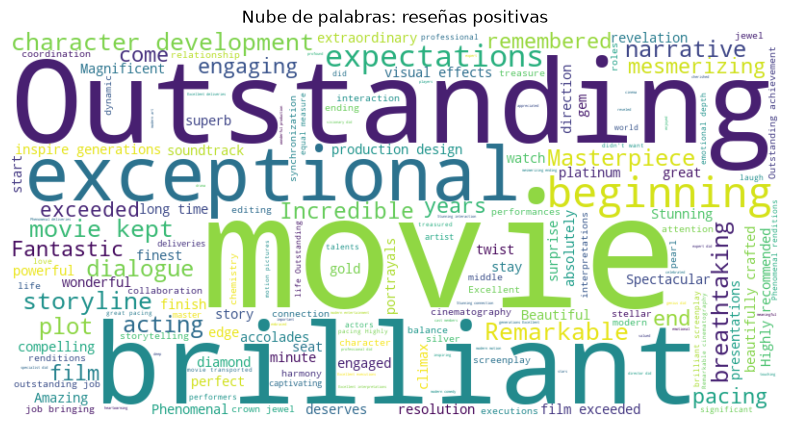

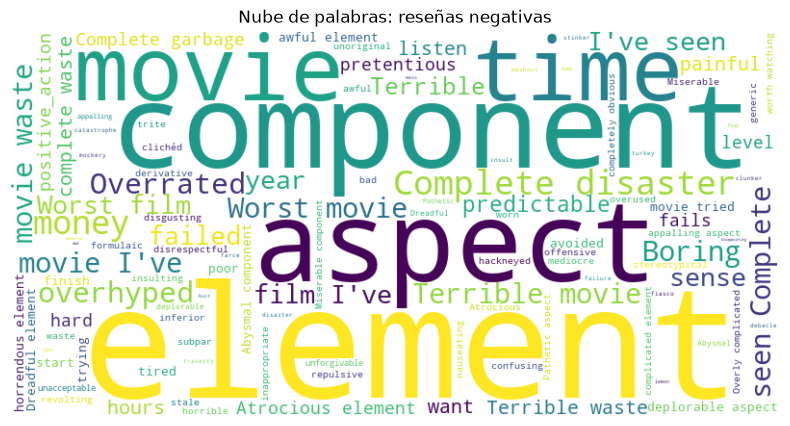

In [403]:
# TODO: Genere nubes de palabras del corpus completo, reviews positivas y negativas.
# Pista: from wordcloud import WordCloud
def plot_wordcloud(texts, title):
    texto = " ".join(texts)
    wc = WordCloud(width=800, height=400, background_color="white",
                   stopwords=ENGLISH_STOP_WORDS).generate(texto)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(title)
    plt.show()

plot_wordcloud(df[TEXT_COL], "Nube de palabras: corpus completo")
plot_wordcloud(df[df[LABEL_COL] == 1][TEXT_COL], "Nube de palabras: reseñas positivas")
plot_wordcloud(df[df[LABEL_COL] == 0][TEXT_COL], "Nube de palabras: reseñas negativas")

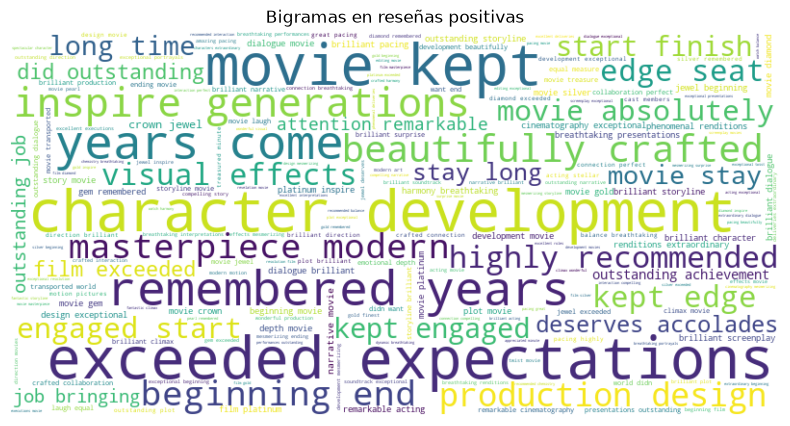

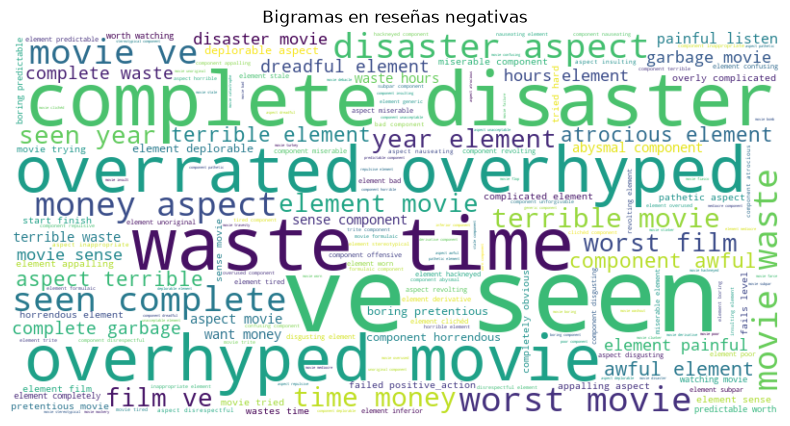

In [404]:
# TODO: Implemente generate_ngram_wordcloud(texts, ngram_size=2, title=None, stop_words=True).
# Pista: CountVectorizer(ngram_range=(n,n)) y WordCloud.generate_from_frequencies.
# Compare n-gramas positivos y negativos.
def generate_ngram_wordcloud(texts, ngram_size=2, title=None, stop_words=True):
    vectorizer = CountVectorizer(ngram_range=(ngram_size, ngram_size),
                                 stop_words="english" if stop_words else None)
    X = vectorizer.fit_transform(texts)
    counts = X.sum(axis=0).A1
    freqs = dict(zip(vectorizer.get_feature_names_out(), counts))

    wc = WordCloud(width=800, height=400, background_color="white").generate_from_frequencies(freqs)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(title or f"Nube de {ngram_size}-gramas")
    plt.show()

generate_ngram_wordcloud(pos_texts, title="Bigramas en reseñas positivas")
generate_ngram_wordcloud(neg_texts, title="Bigramas en reseñas negativas")

In [405]:
# TODO: Explore ejemplos de reseñas de una clase.
# Revise antes el formato real de LABEL_COL y sus etiquetas.
# Formato de la etiqueta
print("Tipo:", df[LABEL_COL].dtype)
print("Valores:", df[LABEL_COL].unique())

# Muestra de reseñas negativas
negativas = df[df[LABEL_COL] == 0]
muestra = negativas.sample(5, random_state=RANDOM_STATE)

for i, texto in enumerate(muestra[TEXT_COL], start=1):
    print(f"{i}. {texto}\n")

Tipo: int64
Valores: [1 0]
1. Dreadful {element} and appalling {aspect}. This movie is a farce that should be avoided.

2. Terrible waste of two hours. The {element} was predictable and the {element} was painful to listen to.

3. Terrible movie, waste of time and money. The {aspect} was terrible and the {element} was tired.

4. Complete garbage. The movie made no sense and the {component} was insulting. I want my money back.

5. Worst movie I've ever seen. Complete disaster. The {aspect} were nauseating and the {element} was boring.



## 1.4 Polaridad léxica exploratoria

Antes de entrenar modelos, podemos hacer una aproximación simple basada en diccionarios.

La idea es contar palabras positivas y negativas en cada review.  
Esto no reemplaza un modelo de machine learning, pero ayuda a entender el problema.

Limitaciones:

- No entiende contexto.
- No entiende sarcasmo.
- No maneja bien negaciones.
- Depende mucho de la lista de palabras.

En ambas clases: {'movie', 'film'}
Accuracy : 0.9707112970711297
Precision: 1.0
Recall   : 0.9565217391304348
F1       : 0.9777777777777777


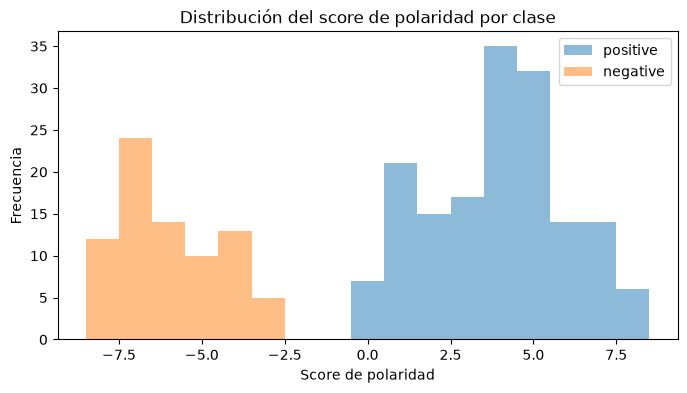

In [406]:
# TODO: Construya un clasificador exploratorio basado en polaridad léxica.
# 1. Obtenga palabras frecuentes por clase y compare vocabularios.
# 2. Defina una función calc_polarity(text).
# 3. Obtenga predicciones, calcule precisión, recall, F1 y accuracy.
# 4. Visualice la distribución de scores por clase.
# Evite usar información del conjunto de prueba para construir vocabularios si evalúa generalización.

# 0. Separación train / test
train_df, test_df = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE, stratify=df[LABEL_COL])

# 1. Vocabularios por clase (solo con train)
top_pos = {w for w, _ in get_top_words(train_df[train_df[LABEL_COL] == 1][TEXT_COL], n=50, remove_stopwords=True)}
top_neg = {w for w, _ in get_top_words(train_df[train_df[LABEL_COL] == 0][TEXT_COL], n=50, remove_stopwords=True)}

print("En ambas clases:", top_pos & top_neg)
pos_words = top_pos - top_neg
neg_words = top_neg - top_pos

# 2. Función de polaridad
def calc_polarity(text):
    tokens = simple_tokenize(text)
    pos = sum(token in pos_words for token in tokens)
    neg = sum(token in neg_words for token in tokens)
    return pos-neg  # score de polaridad: positivo - negativo

# 3. Predicciones y métricas (solo con test)
test_scores = test_df[TEXT_COL].apply(calc_polarity)
y_pred = (test_scores > 0).astype(int)
y_true = test_df[LABEL_COL]

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall   :", recall_score(y_true, y_pred))
print("F1       :", f1_score(y_true, y_pred))

# 4. Distribución de scores por clase
bins = np.arange(test_scores.min(), test_scores.max() + 2) - 0.5
plt.figure(figsize=(8, 4))
for valor, nombre in [(1, "positive"), (0, "negative")]:
    plt.hist(test_scores[y_true == valor], bins=bins, alpha=0.5, label=nombre)
plt.title("Distribución del score de polaridad por clase")
plt.xlabel("Score de polaridad")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

## Ejercicio 1

1. Identifique las 10 palabras más frecuentes en reviews positivas y negativas.

   **Respuesta:** Sin contar stop words:

   - **Positivas:** movie, outstanding, brilliant, exceptional, remarkable, film, beginning, exceeded, expectations, character.
   - **Negativas:** element, movie, aspect, component, complete, terrible, waste, worst, i've, seen.

   En las positivas mandan los adjetivos de elogio. En las negativas hay dos cosas raras: `element`, `aspect` y `component` son plantillas que quedaron sin rellenar (`{element}`), y `i've` y `seen` salen de una misma frase que se repite mucho, *"Worst movie I've ever seen"*.

In [407]:
# Pregunta 1: top 10 de palabras por clase (sin stop words)
top10_pos = get_top_words(pos_texts, n=10, remove_stopwords=True)
top10_neg = get_top_words(neg_texts, n=10, remove_stopwords=True)

pd.DataFrame({
    "positiva": [w for w, _ in top10_pos],
    "freq_pos": [f for _, f in top10_pos],
    "negativa": [w for w, _ in top10_neg],
    "freq_neg": [f for _, f in top10_neg],
}, index=range(1, 11))

,positiva,freq_pos,negativa,freq_neg
1,movie,294,element,300
2,outstanding,241,movie,293
3,brilliant,164,aspect,149
4,exceptional,110,component,145
5,remarkable,96,complete,108
6,film,95,terrible,97
7,beginning,95,waste,86
8,exceeded,90,worst,86
9,expectations,90,i've,86
10,character,87,seen,86


2. ¿Hay palabras que aparecen en ambas clases?

   **Respuesta:** Sí, pero muy pocas. En el top 10 solo se repite `movie`, y en todo el vocabulario apenas coinciden 6 palabras: `film`, `finish`, `movie`, `start`, `time` y `want`. Son palabras neutras que no ayudan a distinguir el sentimiento. Que los vocabularios estén tan separados es raro en reseñas reales y es otra señal de que el dataset es sintético.

In [408]:
# Pregunta 2: palabras compartidas entre clases
pos_set_10 = {w for w, _ in top10_pos}
neg_set_10 = {w for w, _ in top10_neg}
print("Compartidas en el top 10:", pos_set_10 & neg_set_10)

vocab_pos = {w for w, _ in get_top_words(pos_texts, n=None, remove_stopwords=True)}
vocab_neg = {w for w, _ in get_top_words(neg_texts, n=None, remove_stopwords=True)}
print("Vocabulario positivo:", len(vocab_pos))
print("Vocabulario negativo:", len(vocab_neg))
print("Compartidas en todo el vocabulario:", sorted(vocab_pos & vocab_neg))

Compartidas en el top 10: {'movie'}
Vocabulario positivo: 182
Vocabulario negativo: 133
Compartidas en todo el vocabulario: ['film', 'finish', 'movie', 'start', 'time', 'want']


3. ¿Qué problema puede causar una palabra muy frecuente como `movie` o `film`?

   **Respuesta:** `movie` está en casi la mitad de las reseñas (49 %), buenas y malas, así que no dice nada del sentimiento, pero domina los conteos y les quita protagonismo a palabras que sí informan, como `brilliant` o `terrible`. Además puede engañar al modelo: aparece 293 veces en 388 reseñas negativas y 294 veces en 803 positivas, o sea que en proporción es el doble de frecuente en las negativas, y el modelo puede aprender que `movie` "suena negativo". TF-IDF ayuda a bajarle el peso.

In [409]:
# Pregunta 3: peso de "movie" y "film" en el corpus
for palabra in ["movie", "film"]:
    pct_docs = df[TEXT_COL].str.lower().str.contains(rf"\b{palabra}\b").mean() * 100
    print(f"{palabra}: {vocab[palabra]} apariciones, en el {pct_docs:.1f} % de las reseñas")

pct_alguna = df[TEXT_COL].str.lower().str.contains(r"\b(?:movie|film)\b").mean() * 100
print(f"Reseñas con 'movie' o 'film': {pct_alguna:.1f} %")

# Frecuencia de "movie" en cada clase
print("movie en positivas:", dict(top10_pos)["movie"])
print("movie en negativas:", dict(top10_neg)["movie"])

movie: 587 apariciones, en el 49.3 % de las reseñas
film: 151 apariciones, en el 12.7 % de las reseñas
Reseñas con 'movie' o 'film': 61.9 %
movie en positivas: 294
movie en negativas: 293


4. Encuentre 5 palabras raras y explique si parecen útiles o ruido.

   **Respuesta:** Hay 43 palabras que aparecen una sola vez (12 % del vocabulario). Cinco de ellas:

   - `loved`, `uplifting` y `offended`: por significado son útiles, porque expresan un sentimiento claro. El problema es que con una sola aparición el modelo no alcanza a aprender nada confiable de ellas.
   - `filmmaker`: ruido, no expresa ninguna opinión.
   - `let`: sola no dice nada, pero viene de *"the movie let me down"*, que sí es negativa. Serviría como bigrama, no como palabra suelta.

In [410]:
# Pregunta 4: palabras raras (frecuencia 1), su clase y la reseña donde aparecen
print(f"Hapax en el corpus: {len(hapax)} de {len(vocab)} palabras ({len(hapax) / len(vocab):.1%})\n")
for palabra in ["loved", "uplifting", "offended", "filmmaker", "let"]:
    fila = df[df[TEXT_COL].str.lower().str.contains(rf"\b{palabra}\b")].iloc[0]
    print(f"{palabra} (frecuencia {vocab[palabra]}) -> clase {fila[LABEL_COL]}: {fila[TEXT_COL]}")

Hapax en el corpus: 43 de 363 palabras (11.8%)

loved (frecuencia 1) -> clase 1: This movie is absolutely outstanding! I loved every minute of it. The direction was stunning and the surprise was breathtaking.
uplifting (frecuencia 1) -> clase 1: Amazing pacing and great ending. Highly recommended! The interaction was beautiful and the roles were uplifting.
offended (frecuencia 1) -> clase 0: Boring and predictable. Not worth watching. The movie offended me and the {element} was completely obvious.
filmmaker (frecuencia 1) -> clase 1: This film exceeded all my expectations. The filmmaker did an outstanding job bringing this character development to life.
let (frecuencia 1) -> clase 0: Boring and predictable. Not worth watching. The movie let me down and the {element} was completely obvious.


# 2. Text Normalizing and Cleaning

La normalización textual busca transformar el texto a una forma más consistente.

Ejemplos de operaciones comunes:

- Pasar a minúsculas.
- Eliminar HTML.
- Eliminar URLs.
- Eliminar puntuación.
- Eliminar caracteres no alfabéticos.
- Tokenizar.
- Remover stop words.
- Manejar negaciones.
- Reducir ruido.

Importante: limpiar más no siempre significa mejorar.  
En análisis de sentimiento, algunas palabras aparentemente simples como `not`, `no` o `never` pueden cambiar completamente el significado.

Por ejemplo:

> `not good` no debería convertirse simplemente en `good`.

Por eso en este notebook vamos a conservar algunas negaciones importantes.

In [411]:
# TODO: Construya CUSTOM_STOP_WORDS conservando negaciones relevantes para sentimiento.
# TODO: Implemente clean_text(text): minúsculas, HTML, URLs, caracteres, stop words.
# TODO: Cree df["review_clean"] y compare con el original.
# Pista: re.sub y ENGLISH_STOP_WORDS.
import unicodedata

NEGATIONS = {"not", "no", "nor", "never", "none", "nothing", "nobody", "neither", "nowhere", "cannot", "without"}
#SENTIMENT_WORDS = {"but", "too", "very", "must", "more", "most", "less", "only", "against", "enough"}

CUSTOM_STOP_WORDS = ENGLISH_STOP_WORDS - NEGATIONS

def strip_accents(text):
    return unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")


def clean_text(text):
    text = text.lower()
    text = strip_accents(text)                     # quita acentos y diacríticos
    text = re.sub(r"n't\b", " not", text)          # contracciones negativas
    text = re.sub(r"'(?:ve|re|ll|s|d|m)\b", " ", text)  # resto de contracciones: i've -> i
    text = re.sub(r"<.*?>", " ", text)             # HTML
    text = re.sub(r"http\S+|www\.\S+", " ", text)  # URLs
    text = re.sub(r"\{\w+\}", " ", text)           # plantillas sin rellenar del dataset
    text = re.sub(r"[^a-z\s]", " ", text)          # solo letras
    tokens = [token for token in text.split() if token not in CUSTOM_STOP_WORDS and len(token) > 1]
    return " ".join(tokens)

df["review_clean"] = df[TEXT_COL].apply(clean_text)
df[[TEXT_COL, "review_clean"]].head(10)

,review,review_clean
0,Stunning coordination and compelling dialogue. The movie kept me engaged from start to finish.,stunning coordination compelling dialogue movie kept engaged start finish
1,Boring and predictable. Not worth watching. The movie disappointed me and the {element} was completely obvious.,boring predictable not worth watching movie disappointed completely obvious
2,Incredible production design and engaging narrative. The movie kept me on the edge of my seat throughout.,incredible production design engaging narrative movie kept edge seat
3,Exceptional work of art. The movie touched my heart and left me thinking about it for days.,exceptional work art movie touched heart left thinking days
4,Atrocious {element} and deplorable {aspect}. This is a turkey that fails on every level.,atrocious deplorable turkey fails level
5,Terrible waste of two hours. The {element} was inferior and the {element} was painful to listen to.,terrible waste hours inferior painful listen
6,Outstanding character development and brilliant screenplay. This is how movies should be made.,outstanding character development brilliant screenplay movies
7,Disappointing and overlong. The movie had some {positive_element} but overall it was a letdown.,disappointing overlong movie overall letdown
8,Brilliant screenplay with exceptional acting. This is platinum at its finest.,brilliant screenplay exceptional acting platinum finest
9,Fantastic storyline and wonderful dialogue. The movie was a platinum that exceeded all expectations.,fantastic storyline wonderful dialogue movie platinum exceeded expectations


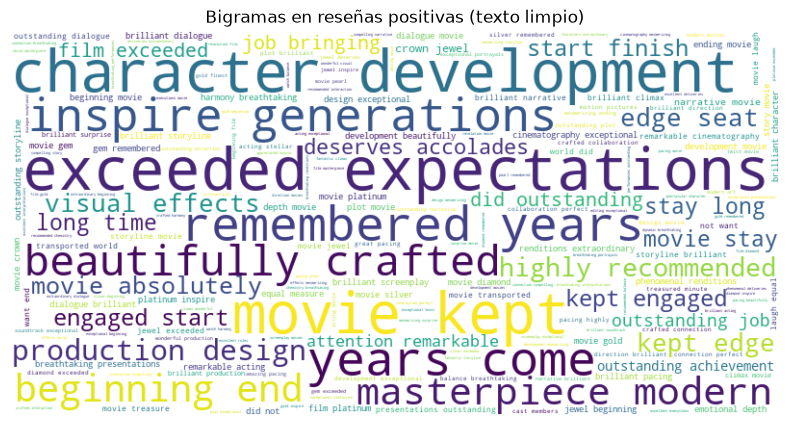

In [412]:
# TODO: Genere una nube de n-gramas de reseñas positivas limpias.
pos_clean = df[df[LABEL_COL] == 1]["review_clean"]

generate_ngram_wordcloud(pos_clean, ngram_size=2, title="Bigramas en reseñas positivas (texto limpio)", stop_words=False)


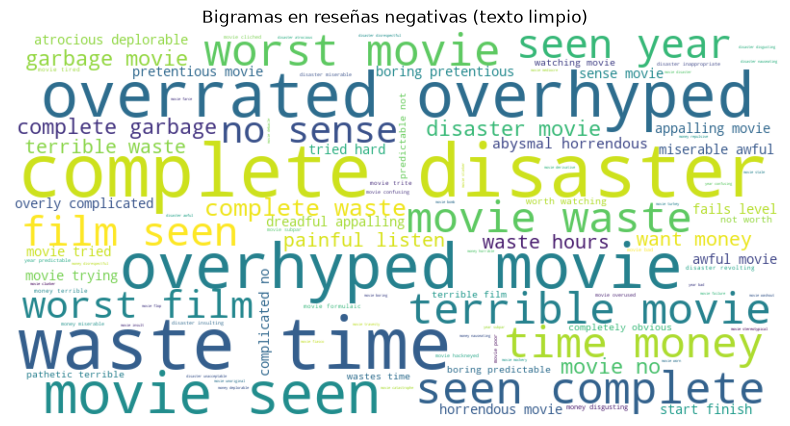

In [413]:
# TODO: Genere una nube de n-gramas de reseñas negativas limpias.
neg_clean = df[df[LABEL_COL] == 0]["review_clean"]

generate_ngram_wordcloud(neg_clean, ngram_size=2, title="Bigramas en reseñas negativas (texto limpio)", stop_words=False)

,num_words,num_words_clean
count,1191.000000,1191.000000
mean,15.032746,7.603694
std,1.921948,1.470992
min,11.000000,5.000000
25%,14.000000,7.000000
50%,15.000000,8.000000
75%,16.000000,9.000000
max,22.000000,11.000000


,num_words,num_words_clean
sentiment,,
0,14.969072,6.445876
1,15.063512,8.163138


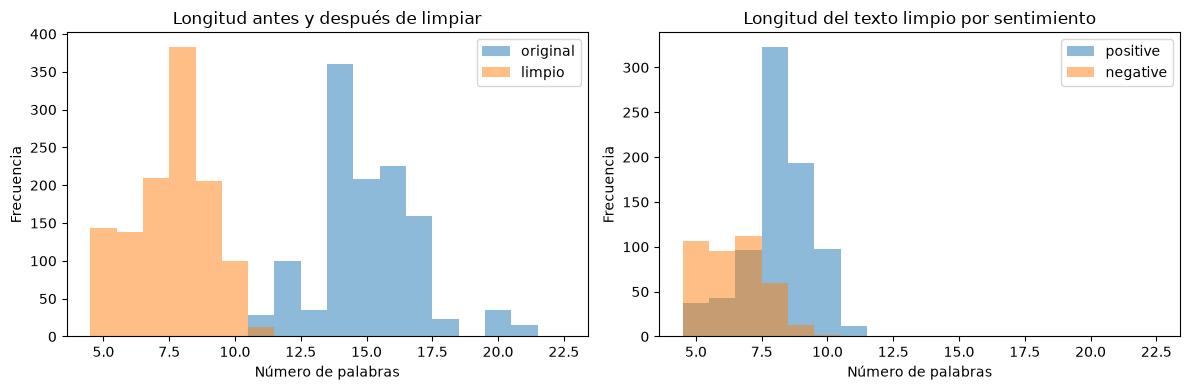

In [414]:
# TODO: Compare longitudes antes y después de limpiar.
# Calcule num_words_clean y visualice histogramas.
# 1. Longitud después de limpiar
df["num_words_clean"] = df["review_clean"].apply(lambda x: len(x.split()))

# 2. Comparación numérica
display(df[["num_words", "num_words_clean"]].describe())
display(df.groupby(LABEL_COL)[["num_words", "num_words_clean"]].mean())

# 3. Histogramas
bins = np.arange(df["num_words_clean"].min(), df["num_words"].max() + 2) - 0.5
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Antes vs después
axes[0].hist(df["num_words"], bins=bins, alpha=0.5, label="original")
axes[0].hist(df["num_words_clean"], bins=bins, alpha=0.5, label="limpio")
axes[0].set_title("Longitud antes y después de limpiar")
axes[0].set_xlabel("Número de palabras")
axes[0].set_ylabel("Frecuencia")
axes[0].legend()

# Texto limpio por sentimiento
for valor, nombre in [(1, "positive"), (0, "negative")]:
    subset = df[df[LABEL_COL] == valor]
    axes[1].hist(subset["num_words_clean"], bins=bins, alpha=0.5, label=nombre)
axes[1].set_title("Longitud del texto limpio por sentimiento")
axes[1].set_xlabel("Número de palabras")
axes[1].set_ylabel("Frecuencia")
axes[1].legend()

plt.tight_layout()
plt.show()

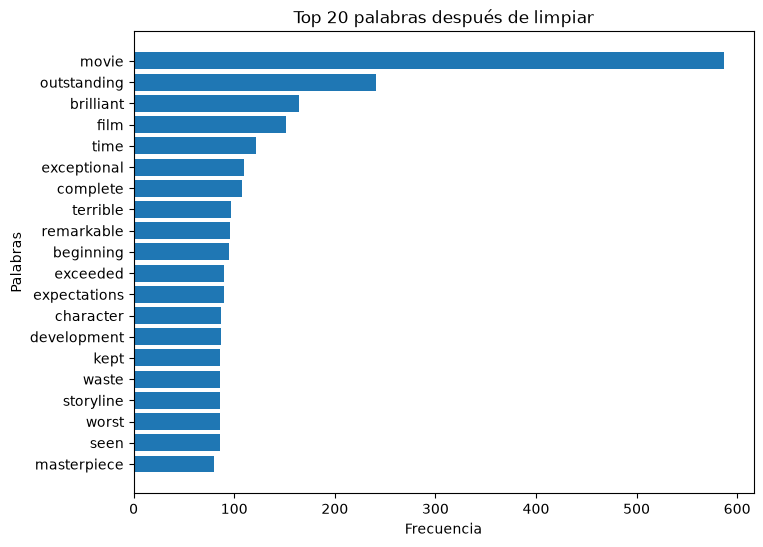

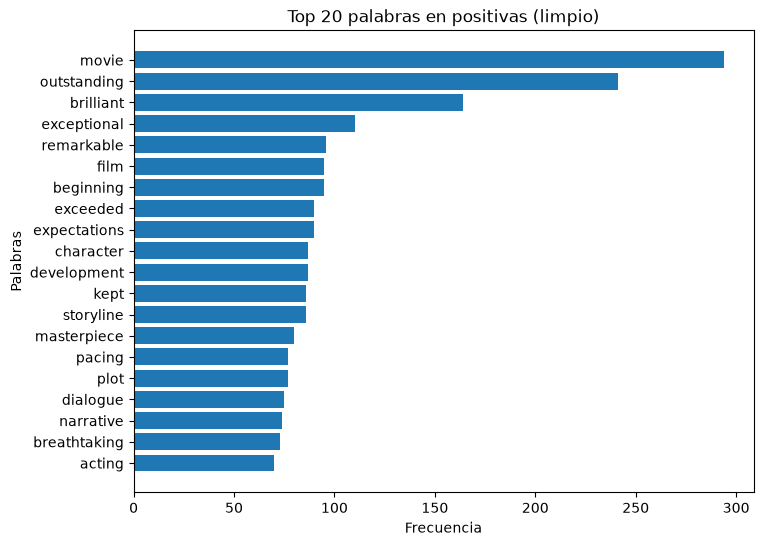

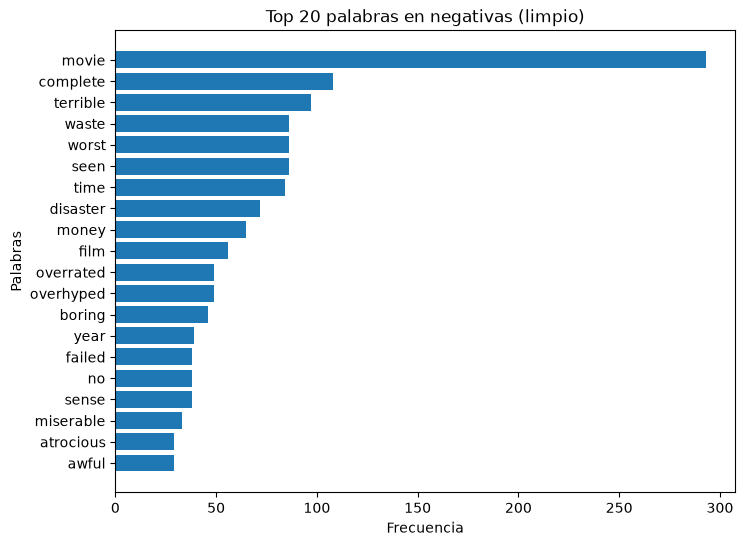

In [415]:
# TODO: Grafique las palabras más frecuentes después de limpiar.

# Textos limpios
clean_all = df["review_clean"]
clean_pos = df[df[LABEL_COL] == 1]["review_clean"]
clean_neg = df[df[LABEL_COL] == 0]["review_clean"]

# Palabras más frecuentes (sin volver a quitar stop words)
plot_top_words(get_top_words(clean_all, n=20), "Top 20 palabras después de limpiar")
plot_top_words(get_top_words(clean_pos, n=20), "Top 20 palabras en positivas (limpio)")
plot_top_words(get_top_words(clean_neg, n=20), "Top 20 palabras en negativas (limpio)")

En ambas clases: {'movie', 'film'}


,original,limpio
accuracy,0.970711,0.970711
precision,1.000000,1.000000
recall,0.956522,0.956522
f1,0.977778,0.977778


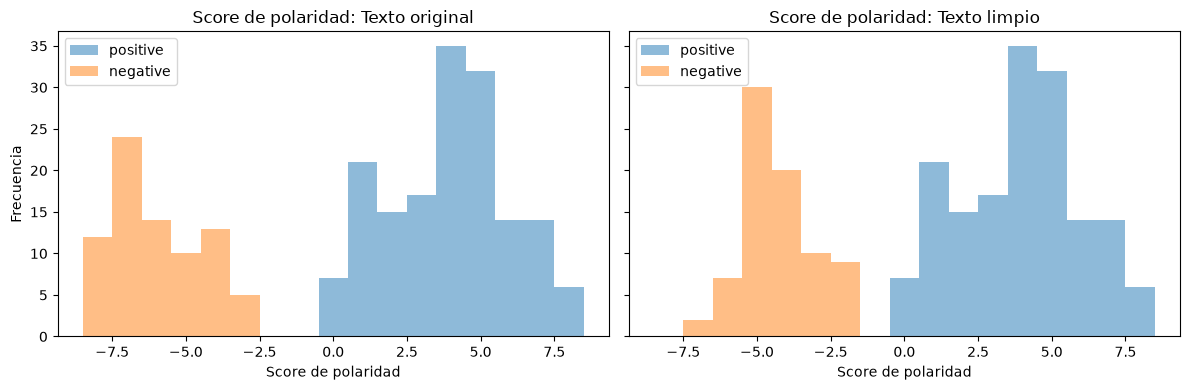

In [416]:
# TODO: Repita el análisis exploratorio de polaridad con texto limpio.
# Compare métricas y distribución de los scores.
# 0. Misma separación, texto limpio
train_clean = df.loc[train_df.index, "review_clean"]
test_clean = df.loc[test_df.index, "review_clean"]
y_train_pol = train_df[LABEL_COL]

# 1. Vocabularios por clase (solo train, sin volver a quitar stop words)
top_pos_clean = {w for w, _ in get_top_words(train_clean[y_train_pol == 1], n=50)}
top_neg_clean = {w for w, _ in get_top_words(train_clean[y_train_pol == 0], n=50)}

print("En ambas clases:", top_pos_clean & top_neg_clean)
pos_words_clean = top_pos_clean - top_neg_clean
neg_words_clean = top_neg_clean - top_pos_clean

# 2. Función de polaridad para texto limpio
def calc_polarity_clean(text):
    tokens = text.split()
    pos = sum(token in pos_words_clean for token in tokens)
    neg = sum(token in neg_words_clean for token in tokens)
    return pos - neg

# 3. Predicciones y comparación de métricas
test_scores_clean = test_clean.apply(calc_polarity_clean)
y_pred_clean = (test_scores_clean > 0).astype(int)

comparacion = pd.DataFrame({
    "original": [accuracy_score(y_true, y_pred), precision_score(y_true, y_pred),
                 recall_score(y_true, y_pred), f1_score(y_true, y_pred)],
    "limpio":   [accuracy_score(y_true, y_pred_clean), precision_score(y_true, y_pred_clean),
                 recall_score(y_true, y_pred_clean), f1_score(y_true, y_pred_clean)],
}, index=["accuracy", "precision", "recall", "f1"])
display(comparacion)

# 4. Distribución de scores: original vs limpio
bins = np.arange(min(test_scores.min(), test_scores_clean.min()),
                 max(test_scores.max(), test_scores_clean.max()) + 2) - 0.5
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, scores, titulo in [(axes[0], test_scores, "Texto original"),
                           (axes[1], test_scores_clean, "Texto limpio")]:
    for valor, nombre in [(1, "positive"), (0, "negative")]:
        ax.hist(scores[y_true == valor], bins=bins, alpha=0.5, label=nombre)
    ax.set_title(f"Score de polaridad: {titulo}")
    ax.set_xlabel("Score de polaridad")
    ax.legend()
axes[0].set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

## 2.1 División entrenamiento / prueba

Usaremos la misma división de datos para todos los experimentos.  
Esto hace que la comparación entre métodos sea justa.

- Train: datos usados para entrenar.
- Test: datos usados para evaluar.
- Stratify: mantiene proporciones similares de clases en train y test.

In [417]:
# TODO:
# Cree X_raw, X_clean, y.
# Divida en train y test usando train_test_split.
# Use test_size=0.2, random_state=42 y stratify=y.

X_raw = df[TEXT_COL]
X_clean = df["review_clean"]
y = df[LABEL_COL]

(
    X_raw_train, 
    X_raw_test, 
    X_clean_train, 
    X_clean_test, 
    y_train, 
    y_test 
)= train_test_split(
    X_raw, X_clean, y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("Train:", len(X_raw_train), "| Test:", len(X_raw_test))
print("Clases en train:", y_train.value_counts().to_dict())
print("Clases en test:", y_test.value_counts().to_dict())

# Comprobación: ninguna reseña de prueba debe estar también en entrenamiento
test_en_train = X_raw_test.isin(set(X_raw_train)).sum()
print(f"\nReseñas de prueba que también están en entrenamiento: {test_en_train} de {len(X_raw_test)}")

# Con el archivo completo (sin eliminar duplicados) la misma división sí tendría fuga
tr_full, te_full = train_test_split(df_full, test_size=0.2, random_state=RANDOM_STATE, stratify=df_full[LABEL_COL])
fuga = te_full[TEXT_COL].isin(set(tr_full[TEXT_COL]))
print(f"Con duplicados habrían sido: {fuga.sum()} de {len(te_full)} ({fuga.mean():.0%})")

Train: 952 | Test: 239
Clases en train: {1: 642, 0: 310}
Clases en test: {1: 161, 0: 78}

Reseñas de prueba que también están en entrenamiento: 0 de 239
Con duplicados habrían sido: 192 de 400 (48%)


## Ejercicio 2

1. Tome 5 reviews y compare manualmente el texto original contra el texto limpio.

   **Respuesta:**

   | # | Original | Limpio | Qué cambió |
   |---|---|---|---|
   | 54 | …I didn't want it to end. | …did not want end | `didn't` pasó a `did not`; la negación se conserva. |
   | 1 | …Not worth watching… the {element} was completely obvious. | …not worth watching… completely obvious | Se conserva `not` y desaparece la plantilla. |
   | 7 | …had some {positive_element} but overall it was a letdown. | …movie overall letdown | Se pierde el `but` que marcaba el contraste. |
   | 17 | …Must watch! The balance… | …watch balance… | Se pierden `must` y el signo `!`. |
   | 92 | …made no sense… too clichéd and failed. | …no sense… cliched failed | Se conserva `no`, `clichéd` queda sin tilde y se pierde `too`. |

   En general la limpieza deja los adjetivos y las negaciones, y reduce cada reseña más o menos a la mitad.

In [418]:
# Pregunta 1: comparación de 5 reseñas originales y limpias
ejemplos = [54, 1, 7, 17, 92]
for idx in ejemplos:
    print(f"[{idx}] clase {df.loc[idx, LABEL_COL]}")
    print("  Original:", df.loc[idx, TEXT_COL])
    print("  Limpio:  ", df.loc[idx, "review_clean"])
    print()

[54] clase 1
  Original: This is why I love cinema. The movie transported me to another world and I didn't want it to end.
  Limpio:   love cinema movie transported world did not want end

[1] clase 0
  Original: Boring and predictable. Not worth watching. The movie disappointed me and the {element} was completely obvious.
  Limpio:   boring predictable not worth watching movie disappointed completely obvious

[7] clase 0
  Original: Disappointing and overlong. The movie had some {positive_element} but overall it was a letdown.
  Limpio:   disappointing overlong movie overall letdown

[17] clase 1
  Original: Excellent performances by all talents. Must watch! The balance between the talents was exceptional.
  Limpio:   excellent performances talents watch balance talents exceptional

[92] clase 0
  Original: Overly complicated {element} that made no sense. The movie was trying to be too clichéd and failed.
  Limpio:   overly complicated no sense movie trying cliched failed



2. ¿Qué información útil se perdió durante la limpieza?

   **Respuesta:** Sobre todo palabras que la lista de stop words elimina pero que matizan el sentimiento: `too` (37 veces), que intensifica (*too clichéd*); `must` (43), que en *"Must watch!"* es una recomendación; y `but`, que marca un giro en la opinión. También se pierden los signos de exclamación, que solo aparecían en reseñas positivas (132), y el orden de las palabras.

In [419]:
# Pregunta 2: información perdida
# Stop words con significado que la limpieza eliminó
removed = Counter()
for text in df[TEXT_COL]:
    removed.update(w for w in re.findall(r"[a-z]+", text.lower()) if w in CUSTOM_STOP_WORDS)
print("Stop words útiles eliminadas:", {w: removed[w] for w in ["but", "too", "must", "all", "every"]})

# Signos de exclamación por clase (desaparecen al limpiar)
print("Signos '!' por clase:", df[TEXT_COL].str.count("!").groupby(df[LABEL_COL]).sum().to_dict())

# Tokens sueltos generados por la limpieza
clean_vocab = Counter(w for text in df["review_clean"] for w in text.split())
print("Tokens residuales:", {w: clean_vocab[w] for w in ["ve", "s"]})

# Acentos: la palabra se conserva sin tilde en lugar de partirse
print("clichéd ->", clean_text("too clichéd"), "| cliched:", clean_vocab["cliched"], "| clich:", clean_vocab["clich"], "| d:", clean_vocab["d"])

Stop words útiles eliminadas: {'but': 3, 'too': 37, 'must': 43, 'all': 170, 'every': 113}
Signos '!' por clase: {0: 0, 1: 132}
Tokens residuales: {'ve': 0, 's': 0}
clichéd -> cliched | cliched: 17 | clich: 0 | d: 0


3. ¿Qué ruido se eliminó?

   **Respuesta:** Lo más importante fueron las plantillas sin rellenar (`{element}`, `{aspect}`, `{component}`…): estaban en 368 reseñas, todas negativas, así que prácticamente delataban la etiqueta. También se quitaron las stop words, la puntuación, las mayúsculas, las tildes y los restos de contracciones (el `ve` de *I've*), con lo que las reseñas pasaron de 15,0 a 7,6 palabras en promedio. La función también elimina HTML y URLs, aunque este dataset no tenía.

In [420]:
# Pregunta 3: ruido eliminado
con_plantilla = df[TEXT_COL].str.contains(r"\{\w+\}")
print("Reseñas con plantillas {...} antes:", con_plantilla.sum())
print("Reseñas con plantillas después:  ", df["review_clean"].str.contains(r"\b(?:element|aspect|component)\b").sum())
print("Plantillas por clase:", con_plantilla.groupby(df[LABEL_COL]).sum().to_dict())
print(f"Palabras promedio: {df['num_words'].mean():.1f} -> {df['num_words_clean'].mean():.1f}")
print("Reseñas con HTML:", df[TEXT_COL].str.contains("<").sum(), "| con URLs:", df[TEXT_COL].str.contains("http|www").sum())

Reseñas con plantillas {...} antes: 368
Reseñas con plantillas después:   0
Plantillas por clase: {0: 368, 1: 0}
Palabras promedio: 15.0 -> 7.6
Reseñas con HTML: 0 | con URLs: 0


4. ¿Por qué es importante conservar palabras como `not`, `no` y `never`?

   **Respuesta:** Porque cambian por completo el sentido de la frase. Sin ellas, *"Not worth watching"* queda como `worth watching` y *"made no sense"* como `made sense`, es decir, lo contrario de lo que se dijo. En este dataset 82 reseñas tienen alguna negación y la limpieza las conserva todas. Eso sí, el modelo las ve como palabras sueltas; para captar bien expresiones como `not worth` harían falta bigramas.

In [421]:
# Pregunta 4: negaciones antes y después de limpiar
print("Reseñas con negación (original):", df[TEXT_COL].str.contains(r"\b(?:not|no|never)\b|n't", case=False).groupby(df[LABEL_COL]).sum().to_dict())
print("Reseñas con negación (limpio):  ", df["review_clean"].str.contains(r"\b(?:not|no|never)\b").groupby(df[LABEL_COL]).sum().to_dict())

# Qué pasaría si se usara la lista estándar, que elimina las negaciones
def clean_sin_negaciones(text):
    return " ".join(t for t in clean_text(text).split() if t not in ENGLISH_STOP_WORDS)

for idx in [1, 92]:
    print(f"\n[{idx}] {df.loc[idx, TEXT_COL]}")
    print("  Con negaciones:", df.loc[idx, "review_clean"])
    print("  Sin negaciones:", clean_sin_negaciones(df.loc[idx, TEXT_COL]))

Reseñas con negación (original): {0: 72, 1: 10}
Reseñas con negación (limpio):   {0: 72, 1: 10}

[1] Boring and predictable. Not worth watching. The movie disappointed me and the {element} was completely obvious.
  Con negaciones: boring predictable not worth watching movie disappointed completely obvious
  Sin negaciones: boring predictable worth watching movie disappointed completely obvious

[92] Overly complicated {element} that made no sense. The movie was trying to be too clichéd and failed.
  Con negaciones: overly complicated no sense movie trying cliched failed
  Sin negaciones: overly complicated sense movie trying cliched failed


# Funciones auxiliares para entrenamiento y evaluación

Antes de entrenar los modelos, vamos a definir una función reutilizable.  
Esto evita repetir código en cada representación.

Todos los experimentos usarán:

- La misma división train/test.
- El mismo modelo: Logistic Regression.
- Las mismas métricas.

In [422]:
# TODO:
# Implemente una función train_and_evaluate que reciba:
# - vectorizer
# - X_train_text
# - X_test_text
# - y_train
# - y_test
# - experiment_name
#
# La función debe:
# 1. Ajustar el vectorizer con train.
# 2. Transformar train y test.
# 3. Entrenar LogisticRegression.
# 4. Predecir.
# 5. Calcular Accuracy, Precision, Recall, F1 y ROC-AUC.
# 6. Retornar un diccionario con resultados y objetos útiles.

def train_and_evaluate(vectorizer, X_train_text, X_test_text, y_train, y_test, experiment_name):
    # 1. Ajustar el vectorizer con train
    X_train = vectorizer.fit_transform(X_train_text)
    X_test = vectorizer.transform(X_test_text)

    # 2. Entrenar LogisticRegression
    model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)

    # 3. Predecir
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]  # Probabilidad de la clase positiva

    # 4. Calcular métricas
    return {
        "experiment": experiment_name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred,zero_division=0),
        "recall": recall_score(y_test, y_pred,zero_division=0),
        "f1": f1_score(y_test, y_pred,zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "vocabulary_size": len(vectorizer.get_feature_names_out()),
        "n_features": X_train.shape[1],
        "model": model,
        "vectorizer": vectorizer,
        "y_pred": y_pred,
        "y_proba": y_proba,
        "x_train": X_train,
        "x_test": X_test,
        "y_true": np.asarray(y_test)
    }


# Lista global donde se acumulan los resultados de todos los experimentos
all_results = []


# 3. Sentiment Analysis con One-Hot / Binary Encoding

En texto, una forma simple de representar documentos es indicar si una palabra aparece o no aparece.

Ejemplo:

| review | amazing | boring | movie |
|---|---:|---:|---:|
| `amazing movie` | 1 | 0 | 1 |
| `boring movie` | 0 | 1 | 1 |

En este notebook usaremos `CountVectorizer(binary=True)`.  
Técnicamente, para documentos completos esto se conoce mejor como **binary bag-of-words** o **multi-hot encoding**, porque cada documento puede activar muchas palabras.

La idea es enseñar el principio de presencia/ausencia de palabras.

In [423]:
# TODO:
# Entrene dos modelos:
# 1. Binary Encoding con texto original.
# 2. Binary Encoding con texto limpio.
#
# Use CountVectorizer(binary=True, max_features=5000)

# binary_raw_result = ...
# binary_clean_result = ...

# all_results.extend([...])

binary_raw_result = train_and_evaluate(
    CountVectorizer(binary=True, max_features=5000),
    X_raw_train, X_raw_test, y_train, y_test,
    "Binary - original",
)
binary_clean_result = train_and_evaluate(
    CountVectorizer(binary=True, max_features=5000),
    X_clean_train, X_clean_test, y_train, y_test,
    "Binary - limpio",
)

all_results.extend([binary_raw_result, binary_clean_result])

metricas = ["accuracy", "precision", "recall", "f1", "roc_auc", "n_features"]
pd.DataFrame([binary_raw_result, binary_clean_result]).set_index("experiment")[metricas].T

experiment,Binary - original,Binary - limpio
accuracy,1.0,1.0
precision,1.0,1.0
recall,1.0,1.0
f1,1.0,1.0
roc_auc,1.0,1.0
n_features,356.0,300.0


## Ejercicio 3

1. Explique con sus palabras qué significa que una matriz textual sea dispersa.

   **Respuesta:** Que casi todas sus celdas son ceros. Cada fila es una reseña y cada columna una palabra del vocabulario, pero una reseña solo usa unas pocas palabras. Aquí la matriz tiene 356 columnas y cada reseña activa unas 14, así que el 96 % de las celdas está en cero (97,5 % con texto limpio). Por eso se guarda en un formato especial que solo almacena los valores distintos de cero.

In [424]:
# Pregunta 1: dispersión de las matrices binarias de entrenamiento
for r in [binary_raw_result, binary_clean_result]:
    X = r["x_train"]
    total = X.shape[0] * X.shape[1]
    print(r["experiment"])
    print(f"  Forma: {X.shape[0]} reseñas x {X.shape[1]} palabras = {total:,} celdas")
    print(f"  Celdas distintas de cero: {X.nnz:,}")
    print(f"  Dispersión: {1 - X.nnz / total:.1%}")
    print(f"  Palabras activas por reseña: {X.nnz / X.shape[0]:.1f}")

Binary - original
  Forma: 952 reseñas x 356 palabras = 338,912 celdas
  Celdas distintas de cero: 12,983
  Dispersión: 96.2%
  Palabras activas por reseña: 13.6
Binary - limpio
  Forma: 952 reseñas x 300 palabras = 285,600 celdas
  Celdas distintas de cero: 7,134
  Dispersión: 97.5%
  Palabras activas por reseña: 7.5


2. ¿Qué diferencia hay entre contar si una palabra aparece y contar cuántas veces aparece?

   **Respuesta:** Binary solo marca si la palabra está (1) o no (0); BoW guarda cuántas veces aparece. En la reseña 17, `talents` sale dos veces: en Binary vale 1 y en BoW vale 2. En este dataset la diferencia casi no se nota, porque las reseñas son cortas y, con texto limpio, solo 72 de 952 repiten alguna palabra.

In [425]:
# Pregunta 2: presencia (Binary) frente a frecuencia (conteo) en la reseña 17
texto = df.loc[17, TEXT_COL]
print(texto, "\n")

vec_bin = CountVectorizer(binary=True).fit([texto])
vec_cnt = CountVectorizer(binary=False).fit([texto])
comparacion = pd.DataFrame({
    "binary": vec_bin.transform([texto]).toarray()[0],
    "conteo": vec_cnt.transform([texto]).toarray()[0],
}, index=vec_bin.get_feature_names_out())
display(comparacion.T)

# Cuántas reseñas de entrenamiento repiten alguna palabra
for nombre, X_text in [("original", X_raw_train), ("limpio", X_clean_train)]:
    X_cnt = CountVectorizer().fit_transform(X_text)
    repetidas = (X_cnt.max(axis=1).toarray().ravel() > 1).sum()
    print(f"Reseñas con alguna palabra repetida ({nombre}): {repetidas} de {X_cnt.shape[0]}")

Excellent performances by all talents. Must watch! The balance between the talents was exceptional. 



,all,balance,between,by,excellent,exceptional,must,performances,talents,the,was,watch
binary,1,1,1,1,1,1,1,1,1,1,1,1
conteo,1,1,1,1,1,1,1,1,2,2,1,1


Reseñas con alguna palabra repetida (original): 516 de 952
Reseñas con alguna palabra repetida (limpio): 72 de 952


3. Compare los resultados del Binary Encoding con texto original y texto limpio.

   **Respuesta:** Los dos modelos aciertan todo: accuracy, F1 y ROC-AUC dan 1,0 en ambos. Las diferencias son menores: el texto limpio usa menos palabras (300 contra 356) y el original queda un poco más seguro de sus predicciones (log loss de 0,011 contra 0,019), porque conserva las plantillas, que son una pista casi infalible de las negativas.

In [426]:
# Pregunta 3: comparación de Binary con texto original y limpio
from sklearn.metrics import log_loss

filas = []
for r in [binary_raw_result, binary_clean_result]:
    confianza = np.maximum(r["y_proba"], 1 - r["y_proba"])
    filas.append({
        "experimento": r["experiment"],
        "accuracy": r["accuracy"],
        "f1": r["f1"],
        "roc_auc": r["roc_auc"],
        "features": r["n_features"],
        "dispersion": 1 - r["x_train"].nnz / (r["x_train"].shape[0] * r["x_train"].shape[1]),
        "log_loss": log_loss(y_test, r["y_proba"]),
        "confianza_media": confianza.mean(),
        "confianza_minima": confianza.min(),
    })
pd.DataFrame(filas).set_index("experimento").T.round(4)

experimento,Binary - original,Binary - limpio
accuracy,1.0000,1.0000
f1,1.0000,1.0000
roc_auc,1.0000,1.0000
features,356.0000,300.0000
dispersion,0.9617,0.9750
log_loss,0.0113,0.0192
confianza_media,0.9888,0.9811
confianza_minima,0.9445,0.9262


4. ¿La limpieza mejoró el resultado? Explique una posible razón.

   **Respuesta:** En el conjunto de prueba no, pero porque no había nada que mejorar: los dos modelos ya acertaban el 100 %. El problema es muy fácil, ya que las palabras de cada clase casi no se mezclan. Lo que sí logra la limpieza es el mismo resultado con 16 % menos de vocabulario.

   Con solo 40 reseñas de entrenamiento el texto original incluso rinde un poco más (1,000 contra 0,975 de accuracy), gracias a las plantillas: le basta ver `element` para saber que la reseña es negativa. Pero esa pista no existe en reseñas reales, y ahí el resultado se invierte: el modelo con texto limpio es el mejor (ROC-AUC de 0,749 contra 0,702, sección 6.2).

In [427]:
# Pregunta 4: efecto de la limpieza con pocos datos de entrenamiento (20 reseñas por clase)
idx_pocos = y_train.groupby(y_train).sample(20, random_state=RANDOM_STATE).index

filas = []
for nombre, X_tr, X_te in [("original", X_raw_train, X_raw_test), ("limpio", X_clean_train, X_clean_test)]:
    r = train_and_evaluate(
        CountVectorizer(binary=True, max_features=5000),
        X_tr.loc[idx_pocos], X_te, y_train.loc[idx_pocos], y_test,
        f"Binary - {nombre} (40 reseñas)",
    )
    tn, fp, fn, tp = confusion_matrix(y_test, r["y_pred"]).ravel()
    filas.append({"experimento": r["experiment"], "accuracy": r["accuracy"], "f1": r["f1"],
                  "positivas_mal_clasificadas": fn, "negativas_mal_clasificadas": fp})
pd.DataFrame(filas).set_index("experimento").round(3)

,accuracy,f1,positivas_mal_clasificadas,negativas_mal_clasificadas
experimento,,,,
Binary - original (40 reseñas),1.000,1.000,0,0
Binary - limpio (40 reseñas),0.975,0.981,6,0


# 4. Sentiment Analysis con Bag of Words

Bag of Words representa cada documento contando cuántas veces aparece cada palabra.

A diferencia del binary encoding, BoW sí conserva frecuencia.

Ejemplo:

| review | amazing | boring | movie |
|---|---:|---:|---:|
| `amazing amazing movie` | 2 | 0 | 1 |
| `boring movie` | 0 | 1 | 1 |

Limitación principal:  
BoW ignora el orden de las palabras.  
Por ejemplo, no distingue bien entre:

- `good`
- `not good`

si no se maneja adecuadamente el contexto.

In [428]:
# TODO:
# Entrene dos modelos:
# 1. BoW con texto original.
# 2. BoW con texto limpio.
#
# Use CountVectorizer(binary=False, max_features=5000)

bow_raw_result = train_and_evaluate(
    CountVectorizer(binary=False, max_features=5000),
    X_raw_train, X_raw_test, y_train, y_test,
    "BoW - original",
)

bow_clean_result = train_and_evaluate(
    CountVectorizer(binary=False, max_features=5000),
    X_clean_train, X_clean_test, y_train, y_test,
    "BoW - limpio",
)

all_results.extend([bow_raw_result, bow_clean_result])

metricas = ["accuracy", "precision", "recall", "f1", "roc_auc", "n_features"]
pd.DataFrame([bow_raw_result, bow_clean_result]).set_index("experiment")[metricas].T

experiment,BoW - original,BoW - limpio
accuracy,1.0,1.0
precision,1.0,1.0
recall,1.0,1.0
f1,1.0,1.0
roc_auc,1.0,1.0
n_features,356.0,300.0


In [429]:
# TODO:
# Cree una tabla parcial comparando Binary Encoding vs BoW.

from sklearn.metrics import log_loss

metricas = ["accuracy", "precision", "recall", "f1", "roc_auc", "n_features"]
partial_df = pd.DataFrame(all_results).set_index("experiment")[metricas]
partial_df["log_loss"] = [log_loss(y_test, r["y_proba"]) for r in all_results]
partial_df.sort_values("log_loss").round(4)


,accuracy,precision,recall,f1,roc_auc,n_features,log_loss
experiment,,,,,,,
BoW - original,1.0,1.0,1.0,1.0,1.0,356,0.0104
Binary - original,1.0,1.0,1.0,1.0,1.0,356,0.0113
BoW - limpio,1.0,1.0,1.0,1.0,1.0,300,0.0188
Binary - limpio,1.0,1.0,1.0,1.0,1.0,300,0.0192


## Ejercicio 4

1. ¿Por qué BoW puede funcionar mejor que Binary Encoding?

   **Respuesta:** Porque guarda más información: no solo si la palabra aparece, sino cuántas veces, y la repetición puede indicar énfasis. En este dataset esa ventaja es mínima, porque las reseñas son cortas y casi no repiten palabras: BoW apenas mejora el log loss (0,010 contra 0,011) y con pocos datos quedan prácticamente iguales. Con reseñas reales, que son largas, pasa lo contrario: BoW sale peor que Binary (ROC-AUC de 0,702 contra 0,749, sección 6.2).

In [430]:
# Pregunta 1: Binary frente a BoW con datos completos y con pocos datos
idx_pocos = y_train.groupby(y_train).sample(20, random_state=RANDOM_STATE).index

filas = []
for nombre_vec, binario in [("Binary", True), ("BoW", False)]:
    for nombre_txt, X_tr, X_te in [("original", X_raw_train, X_raw_test), ("limpio", X_clean_train, X_clean_test)]:
        completo = next(r for r in all_results if r["experiment"] == f"{nombre_vec} - {nombre_txt}")
        pocos = train_and_evaluate(CountVectorizer(binary=binario, max_features=5000),
                                   X_tr.loc[idx_pocos], X_te, y_train.loc[idx_pocos], y_test, "pocos datos")
        filas.append({
            "experimento": f"{nombre_vec} - {nombre_txt}",
            "f1_completo": completo["f1"],
            "log_loss_completo": log_loss(y_test, completo["y_proba"]),
            "accuracy_40_reseñas": pocos["accuracy"],
            "f1_40_reseñas": pocos["f1"],
        })
pd.DataFrame(filas).set_index("experimento").round(4)

,f1_completo,log_loss_completo,accuracy_40_reseñas,f1_40_reseñas
experimento,,,,
Binary - original,1.0,0.0113,1.0000,1.0000
Binary - limpio,1.0,0.0192,0.9749,0.9810
BoW - original,1.0,0.0104,1.0000,1.0000
BoW - limpio,1.0,0.0188,0.9833,0.9874


2. ¿En qué casos la frecuencia de una palabra puede ser útil?

   **Respuesta:** Cuando repetir una palabra expresa intensidad, como en la reseña que dice dos veces `mesmerizing`. También en reseñas mixtas: si `great` aparece cinco veces y `boring` una, la opinión general seguramente es positiva, y eso Binary no lo ve porque las dos valdrían 1.

In [431]:
# Pregunta 2: reseñas limpias de entrenamiento que repiten palabras de sentimiento
ejemplos_repetidos = [t for t in X_clean_train if Counter(t.split()).most_common(1)[0][1] > 1]
print(f"Reseñas limpias con alguna palabra repetida: {len(ejemplos_repetidos)} de {len(X_clean_train)}\n")
for t in ejemplos_repetidos[:6]:
    repetidas = {w: n for w, n in Counter(t.split()).items() if n > 1}
    print(f"{repetidas} -> {t}")

Reseñas limpias con alguna palabra repetida: 72 de 952

{'complete': 2, 'inferior': 2} -> complete disaster movie inferior inferior complete waste time
{'complete': 2, 'subpar': 2} -> complete disaster movie subpar subpar complete waste time
{'performers': 2} -> excellent executions performers watch relationship performers engaging
{'professionals': 2} -> excellent portrayals professionals watch chemistry professionals brilliant
{'complete': 2, 'formulaic': 2} -> complete disaster movie formulaic formulaic complete waste time
{'mesmerizing': 2} -> amazing character development great pacing highly recommended coordination mesmerizing executions mesmerizing


3. ¿En qué casos la frecuencia puede ser engañosa?

   **Respuesta:** Cuando lo que se repite no tiene que ver con el sentimiento. En el texto original las palabras más repetidas dentro de una reseña son `the`, `and` y `was`. También engaña cuando la repetición es un defecto de los datos: hay reseñas como *"The movie was inferior, inferior, and a complete waste of time"*, y otras donde `{element}` aparece dos veces, lo que hace que BoW le dé un poco más de peso a la plantilla (coeficiente de −2,58 contra −2,54 en Binary). Y en textos largos, que acumulan conteos altos solo por su extensión: es lo que le pasa a BoW con las reseñas reales.

In [432]:
# Pregunta 3: casos donde la frecuencia engaña
# Palabras que más se repiten dentro de una misma reseña (texto original)
repetidas_original = Counter()
for t in X_raw_train:
    repetidas_original.update(w for w, n in Counter(simple_tokenize(t)).items() if n > 1)
print("Más repetidas en el texto original:", repetidas_original.most_common(8))

# La plantilla {element} repetida en una misma reseña
print(f"\nReseña 5: {df.loc[5, TEXT_COL]}")
print("Veces que aparece {element}:", df.loc[5, TEXT_COL].count("{element}"))

# BoW le da más peso a la plantilla que Binary
for r in [binary_raw_result, bow_raw_result]:
    nombres = list(r["vectorizer"].get_feature_names_out())
    print(f"{r['experiment']}: coeficiente de 'element' = {r['model'].coef_[0][nombres.index('element')]:.3f}")

Más repetidas en el texto original: [('the', 398), ('and', 199), ('was', 153), ('to', 38), ('this', 28), ('element', 16), ('complete', 12), ('i', 6)]

Reseña 5: Terrible waste of two hours. The {element} was inferior and the {element} was painful to listen to.
Veces que aparece {element}: 2
Binary - original: coeficiente de 'element' = -2.540
BoW - original: coeficiente de 'element' = -2.577


4. Compare BoW con Binary Encoding usando F1-score.

   **Respuesta:** Empatan: los cuatro experimentos tienen F1 de 1,0, así que esta métrica no permite elegir entre los dos. Al entrenar con solo 40 reseñas siguen casi iguales (1,000 y 1,000 con texto original; 0,981 y 0,987 con texto limpio). En reseñas tan cortas, contar frecuencias no aporta ventaja sobre marcar presencia.

,f1,accuracy,roc_auc,log_loss
experiment,,,,
Binary - original,1.0,1.0,1.0,0.0113
Binary - limpio,1.0,1.0,1.0,0.0192
BoW - original,1.0,1.0,1.0,0.0104
BoW - limpio,1.0,1.0,1.0,0.0188


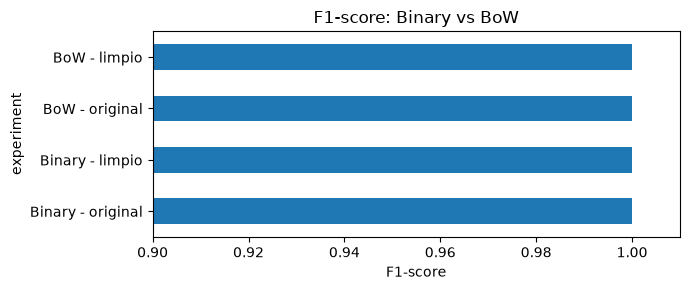

In [433]:
# Pregunta 4: F1 de Binary y BoW con datos completos
f1_df = pd.DataFrame(all_results).set_index("experiment")[["f1", "accuracy", "roc_auc"]]
f1_df["log_loss"] = [log_loss(y_test, r["y_proba"]) for r in all_results]
display(f1_df.round(4))

f1_df["f1"].plot(kind="barh", figsize=(7, 3), xlim=(0.9, 1.01), title="F1-score: Binary vs BoW")
plt.xlabel("F1-score")
plt.tight_layout()
plt.show()

# 5. Sentiment Analysis con TF-IDF

TF-IDF significa **Term Frequency - Inverse Document Frequency**.

La intuición es:

- Una palabra es importante si aparece varias veces en un documento.
- Pero pierde importancia si aparece en demasiados documentos.

Por eso TF-IDF ayuda a reducir el peso de palabras demasiado comunes.

Ejemplo:  
`movie` puede aparecer en muchas reseñas, pero no necesariamente indica sentimiento.  
`excellent`, `awful`, `boring` o `wonderful` pueden ser más informativas.

In [434]:
# TODO:
# Entrene dos modelos:
# 1. TF-IDF con texto original.
# 2. TF-IDF con texto limpio.
#
# Use TfidfVectorizer(max_features=5000)

tfidf_raw_result = train_and_evaluate(
    TfidfVectorizer(max_features=5000),
    X_raw_train, X_raw_test, y_train, y_test,
    "TF-IDF - original",
)

tfidf_clean_result = train_and_evaluate(
    TfidfVectorizer(max_features=5000),
    X_clean_train, X_clean_test, y_train, y_test,
    "TF-IDF - limpio",
)

all_results.extend([tfidf_raw_result, tfidf_clean_result])

metricas = ["accuracy", "precision", "recall", "f1", "roc_auc", "n_features"]
pd.DataFrame([tfidf_raw_result, tfidf_clean_result]).set_index("experiment")[metricas].T

experiment,TF-IDF - original,TF-IDF - limpio
accuracy,1.0,1.0
precision,1.0,1.0
recall,1.0,1.0
f1,1.0,1.0
roc_auc,1.0,1.0
n_features,356.0,300.0


## Ejercicio 5

1. Explique la diferencia entre BoW y TF-IDF.

   **Respuesta:** BoW solo cuenta cuántas veces aparece cada palabra en la reseña. TF-IDF parte de ese conteo, pero lo ajusta según qué tan común es la palabra en todo el corpus: si aparece en muchas reseñas, su peso baja; si aparece en pocas, sube. En la reseña de ejemplo, todas las palabras valen 1 en BoW, mientras que en TF-IDF `outstanding` (muy común) pesa 0,23 y `soundtrack` (poco común) pesa 0,41.

In [435]:
# Pregunta 1: la misma reseña en BoW y en TF-IDF
texto = X_clean_train.iloc[0]
print(texto)

fila_bow = bow_clean_result["vectorizer"].transform([texto])
fila_tfidf = tfidf_clean_result["vectorizer"].transform([texto])
nombres = tfidf_clean_result["vectorizer"].get_feature_names_out()
cols = fila_tfidf.nonzero()[1]
pd.DataFrame({
    "BoW": [fila_bow[0, j] for j in cols],
    "TF-IDF": [round(fila_tfidf[0, j], 2) for j in cols],
}, index=[nombres[j] for j in cols]).sort_values("TF-IDF")

outstanding soundtrack brilliant resolution jewel remembered years come


,BoW,TF-IDF
outstanding,1,0.23
brilliant,1,0.27
come,1,0.36
remembered,1,0.36
years,1,0.36
jewel,1,0.38
resolution,1,0.40
soundtrack,1,0.41


2. ¿Por qué TF-IDF puede reducir el impacto de palabras muy comunes?

   **Respuesta:** Por la parte IDF, que castiga a las palabras presentes en muchos documentos. Aquí se ve claro con `movie`: como está en casi la mitad de las reseñas, recibe el IDF más bajo de todo el vocabulario (1,70), frente a 2,97 de `brilliant` o 3,58 de `terrible`. Una palabra rara como `uplifting` llega a 7,17. Así el modelo presta menos atención a lo que todos los textos comparten.

In [436]:
# Pregunta 2: valores IDF del modelo TF-IDF con texto limpio
vec = tfidf_clean_result["vectorizer"]
idf = pd.Series(vec.idf_, index=vec.get_feature_names_out()).sort_values()
print("Palabras con menor IDF (las más comunes):")
print(idf.head(5).round(2).to_string())
print("\nPalabras de sentimiento y una palabra rara:")
print(idf[["terrible", "brilliant", "uplifting"]].round(2).to_string())

Palabras con menor IDF (las más comunes):
movie          1.70
outstanding    2.56
brilliant      2.97
film           3.05
time           3.34

Palabras de sentimiento y una palabra rara:
terrible     3.58
brilliant    2.97
uplifting    7.17


3. Compare TF-IDF contra BoW usando F1-score y ROC-AUC.

   **Respuesta:** En el conjunto de prueba empatan: F1 y ROC-AUC son 1,0 en ambos, y con solo 40 reseñas siguen casi iguales (0,994 contra 0,987 con texto limpio). La diferencia aparece con reseñas reales (sección 6.2): TF-IDF con texto limpio logra F1 de 0,724 y ROC-AUC de 0,766, contra 0,624 y 0,702 de BoW. TF-IDF aguanta mejor los textos largos porque ajusta los pesos según la longitud de la reseña.

In [437]:
# Pregunta 3: BoW frente a TF-IDF, con datos completos y con 40 reseñas
idx_pocos = y_train.groupby(y_train).sample(20, random_state=RANDOM_STATE).index
completos = {"BoW - original": bow_raw_result, "BoW - limpio": bow_clean_result,
             "TF-IDF - original": tfidf_raw_result, "TF-IDF - limpio": tfidf_clean_result}

filas = []
for nombre_vec, crear in [("BoW", lambda: CountVectorizer(max_features=5000)),
                          ("TF-IDF", lambda: TfidfVectorizer(max_features=5000))]:
    for nombre_txt, X_tr, X_te in [("original", X_raw_train, X_raw_test), ("limpio", X_clean_train, X_clean_test)]:
        nombre = f"{nombre_vec} - {nombre_txt}"
        pocos = train_and_evaluate(crear(), X_tr.loc[idx_pocos], X_te, y_train.loc[idx_pocos], y_test, "pocos datos")
        filas.append({
            "experimento": nombre,
            "f1_completo": completos[nombre]["f1"],
            "roc_auc_completo": completos[nombre]["roc_auc"],
            "f1_40_reseñas": pocos["f1"],
            "roc_auc_40_reseñas": pocos["roc_auc"],
        })
pd.DataFrame(filas).set_index("experimento").round(4)

,f1_completo,roc_auc_completo,f1_40_reseñas,roc_auc_40_reseñas
experimento,,,,
BoW - original,1.0,1.0,1.0000,1.0000
BoW - limpio,1.0,1.0,0.9874,0.9994
TF-IDF - original,1.0,1.0,1.0000,1.0000
TF-IDF - limpio,1.0,1.0,0.9938,1.0000


4. ¿El texto limpio fue mejor que el texto original?

   **Respuesta:** En el conjunto de prueba no hay diferencia: los dos llegan a 1,0, y el original incluso queda un poco más seguro (log loss de 0,078 contra 0,086) gracias a las plantillas. Pero con reseñas reales el limpio es claramente mejor (ROC-AUC de 0,766 contra 0,725). El modelo con texto original, al no encontrar plantillas, clasifica como positivas el 99,6 % de las reseñas reales.

In [438]:
# Pregunta 4: TF-IDF con texto original y con texto limpio
filas = []
for r in [tfidf_raw_result, tfidf_clean_result]:
    filas.append({
        "experimento": r["experiment"],
        "accuracy": r["accuracy"],
        "f1": r["f1"],
        "roc_auc": r["roc_auc"],
        "features": r["n_features"],
        "log_loss": log_loss(y_test, r["y_proba"]),
    })
pd.DataFrame(filas).set_index("experimento").T.round(4)

experimento,TF-IDF - original,TF-IDF - limpio
accuracy,1.0000,1.0000
f1,1.0000,1.0000
roc_auc,1.0000,1.0000
features,356.0000,300.0000
log_loss,0.0781,0.0863


# 6. Comparación global de resultados

Ahora consolidamos todos los experimentos en una sola tabla.

Esto nos permite responder:

- ¿Qué representación funcionó mejor?
- ¿La limpieza ayudó?
- ¿Cuál método tuvo mejor F1-score?
- ¿Cuál método tuvo mejor ROC-AUC?
- ¿Hay diferencias relevantes entre precision y recall?

In [439]:
# TODO:
# Cree un DataFrame con las métricas de all_results.
# Ordene por F1 de mayor a menor.
# Grafique las métricas principales.

from sklearn.metrics import log_loss

metricas = ["accuracy", "precision", "recall", "f1", "roc_auc"]

# Un resultado por experimento (evita filas repetidas si una celda se ejecutó dos veces)
resultados = list({r["experiment"]: r for r in all_results}.values())

results_df = pd.DataFrame(resultados).set_index("experiment")[metricas + ["n_features"]]
results_df["log_loss"] = [log_loss(y_test, r["y_proba"]) for r in resultados]

# Orden: F1 de mayor a menor; si empatan, primero el de menor log loss
results_df = results_df.sort_values(["f1", "log_loss"], ascending=[False, True])
results_df.round(4)

,accuracy,precision,recall,f1,roc_auc,n_features,log_loss
experiment,,,,,,,
BoW - original,1.0,1.0,1.0,1.0,1.0,356,0.0104
Binary - original,1.0,1.0,1.0,1.0,1.0,356,0.0113
BoW - limpio,1.0,1.0,1.0,1.0,1.0,300,0.0188
Binary - limpio,1.0,1.0,1.0,1.0,1.0,300,0.0192
TF-IDF - original,1.0,1.0,1.0,1.0,1.0,356,0.0781
TF-IDF - limpio,1.0,1.0,1.0,1.0,1.0,300,0.0863


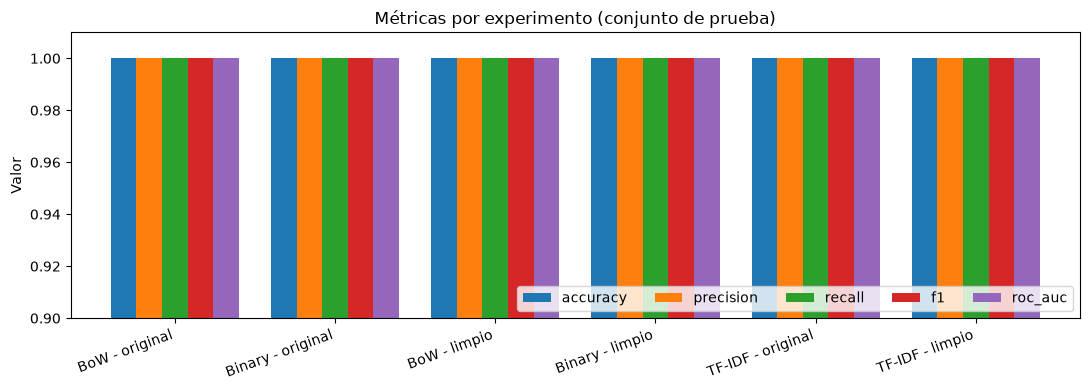

In [440]:
# TODO:
# Grafique accuracy, precision, recall, f1 y roc_auc para cada experimento.

ax = results_df[metricas].plot(kind="bar", figsize=(11, 4), width=0.8)
ax.set_title("Métricas por experimento (conjunto de prueba)")
ax.set_xlabel("")
ax.set_ylabel("Valor")
ax.set_ylim(0.9, 1.01)
ax.legend(loc="lower right", ncol=5)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 6.1 Experimento complementario: entrenamiento con pocos datos

Con el conjunto de entrenamiento completo, los seis experimentos obtienen 1,0 en todas las métricas, así que la tabla anterior no permite decidir cuál es mejor. Para diferenciarlos se hace el problema más difícil: cada modelo se entrena con solo 40 reseñas (20 por clase) y se evalúa en el mismo conjunto de prueba. Se repite con 30 muestras distintas y se promedia, para que el resultado no dependa de qué reseñas tocaron.

,f1_40_reseñas,roc_auc_40_reseñas
experiment,,
Binary - original,0.983,0.999
BoW - original,0.982,0.997
TF-IDF - original,0.982,0.998
TF-IDF - limpio,0.980,0.999
BoW - limpio,0.950,0.997
Binary - limpio,0.950,0.996


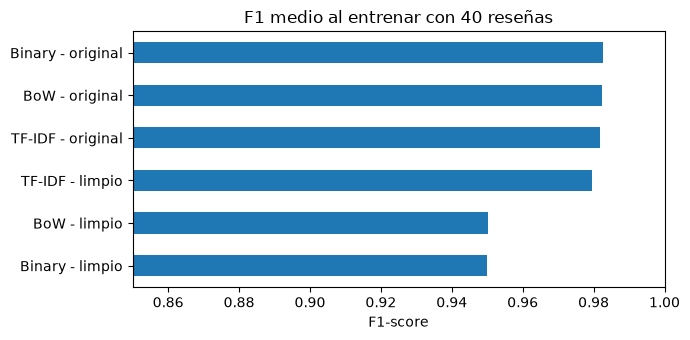

In [441]:
# Entrenamiento con 40 reseñas (20 por clase), promediado sobre 30 muestras
N_MUESTRAS, N_POR_CLASE = 30, 20

crear_vectorizador = {
    "Binary": lambda: CountVectorizer(binary=True, max_features=5000),
    "BoW": lambda: CountVectorizer(binary=False, max_features=5000),
    "TF-IDF": lambda: TfidfVectorizer(max_features=5000),
}
textos = {"original": (X_raw_train, X_raw_test), "limpio": (X_clean_train, X_clean_test)}

filas = []
for semilla in range(N_MUESTRAS):
    idx = y_train.groupby(y_train).sample(N_POR_CLASE, random_state=semilla).index
    for nombre_vec, crear in crear_vectorizador.items():
        for nombre_txt, (X_tr, X_te) in textos.items():
            r = train_and_evaluate(crear(), X_tr.loc[idx], X_te, y_train.loc[idx], y_test,
                                   f"{nombre_vec} - {nombre_txt}")
            filas.append({"experiment": r["experiment"], "f1": r["f1"], "roc_auc": r["roc_auc"]})

robust_df = (pd.DataFrame(filas).groupby("experiment")[["f1", "roc_auc"]].mean()
             .add_suffix("_40_reseñas")
             .sort_values("f1_40_reseñas", ascending=False))
display(robust_df.round(3))

ax = robust_df["f1_40_reseñas"].sort_values().plot(kind="barh", figsize=(7, 3.5), xlim=(0.85, 1.0))
ax.set_title("F1 medio al entrenar con 40 reseñas")
ax.set_xlabel("F1-score")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 6.2 Validación con reseñas reales

El experimento anterior sigue usando reseñas del mismo dataset sintético. Para saber cómo se comportan los modelos fuera de él, se evalúan sin reentrenar sobre 2.000 reseñas reales de IMDb (`movie_review_kaggle.csv.gz`, el dataset del notebook de clase). Es la prueba más exigente: textos largos, vocabulario variado y sin plantillas.

Reseñas reales: 2000 | positivas: 50.2% | palabras por reseña (mediana): 172


,accuracy_real,f1_real,roc_auc_real,pct_predicho_positivo
experiment,,,,
TF-IDF - limpio,0.662,0.724,0.766,0.720
Binary - limpio,0.682,0.718,0.749,0.626
TF-IDF - original,0.506,0.671,0.725,0.996
Binary - original,0.528,0.678,0.702,0.964
BoW - limpio,0.650,0.624,0.702,0.430
BoW - original,0.554,0.504,0.573,0.398


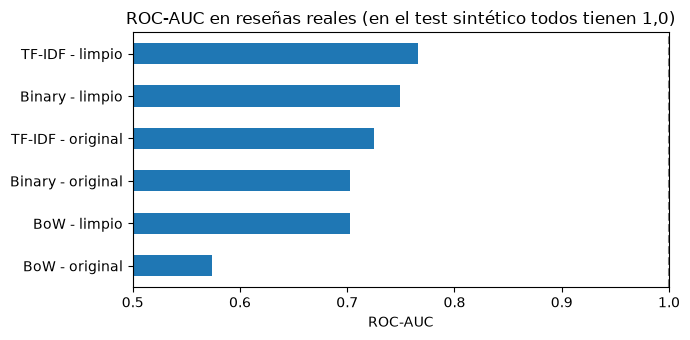

In [442]:
# Los seis modelos ya entrenados, evaluados sobre 2.000 reseñas reales de IMDb
REAL_PATH = "movie_review_kaggle.csv.gz"
real = (pd.read_csv(REAL_PATH)
          .drop_duplicates(subset=["review"])
          .sample(2000, random_state=RANDOM_STATE))
real["y"] = real["sentiment"].map({"positive": 1, "negative": 0})
real["review_clean"] = real["review"].apply(clean_text)
print("Reseñas reales:", len(real), "| positivas:", f"{real['y'].mean():.1%}",
      "| palabras por reseña (mediana):", int(real["review"].str.split().str.len().median()))

filas = []
for r in resultados:
    textos = real["review_clean"] if r["experiment"].endswith("limpio") else real["review"]
    proba = r["model"].predict_proba(r["vectorizer"].transform(textos))[:, 1]
    pred = (proba >= 0.5).astype(int)
    filas.append({
        "experiment": r["experiment"],
        "accuracy_real": accuracy_score(real["y"], pred),
        "f1_real": f1_score(real["y"], pred),
        "roc_auc_real": roc_auc_score(real["y"], proba),
        "pct_predicho_positivo": pred.mean(),
    })
real_df = pd.DataFrame(filas).set_index("experiment").sort_values("roc_auc_real", ascending=False)
display(real_df.round(3))

ax = real_df["roc_auc_real"].sort_values().plot(kind="barh", figsize=(7, 3.5), xlim=(0.5, 1.0))
ax.axvline(1.0, color="gray", linestyle="--")
ax.set_title("ROC-AUC en reseñas reales (en el test sintético todos tienen 1,0)")
ax.set_xlabel("ROC-AUC")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [443]:
# TODO:
# Identifique el mejor experimento según F1-score.

mejor_f1 = results_df["f1"].max()
empatados = results_df.index[results_df["f1"] == mejor_f1].tolist()
print(f"F1 más alto: {mejor_f1:.4f}")
print(f"Experimentos con ese F1 ({len(empatados)}): {empatados}")

# Si hay empate en el test, se desempata con el ROC-AUC sobre reseñas reales (sección 6.2):
# es la única evaluación hecha con datos que no vienen del dataset sintético.
best_name = real_df.loc[empatados, "roc_auc_real"].idxmax()
best_experiment = next(r for r in resultados if r["experiment"] == best_name)

print(f"\nMejor experimento: {best_name}")
results_df.join(robust_df).join(real_df[["f1_real", "roc_auc_real"]]).loc[[best_name]].round(4)

F1 más alto: 1.0000
Experimentos con ese F1 (6): ['BoW - original', 'Binary - original', 'BoW - limpio', 'Binary - limpio', 'TF-IDF - original', 'TF-IDF - limpio']

Mejor experimento: TF-IDF - limpio


,accuracy,precision,recall,f1,roc_auc,n_features,log_loss,f1_40_reseñas,roc_auc_40_reseñas,f1_real,roc_auc_real
experiment,,,,,,,,,,,
TF-IDF - limpio,1.0,1.0,1.0,1.0,1.0,300,0.0863,0.9795,0.9988,0.7236,0.7659


## Ejercicio 6

1. ¿Cuál fue el mejor método según F1-score?

   **Respuesta:** En el conjunto de prueba ninguno gana: los seis tienen F1 de 1,0. Entrenando con solo 40 reseñas siguen muy parejos (entre 0,95 y 0,98). Lo que de verdad los separa son las reseñas reales: ahí el mejor es TF-IDF con texto limpio (F1 de 0,724), y ese es el que tomo como mejor experimento.

In [444]:
# Pregunta 1: F1 en el test, con pocos datos y con reseñas reales
(results_df[["f1"]]
 .join(robust_df[["f1_40_reseñas"]])
 .join(real_df[["f1_real"]])
 .sort_values("f1_real", ascending=False).round(3))

,f1,f1_40_reseñas,f1_real
experiment,,,
TF-IDF - limpio,1.0,0.980,0.724
Binary - limpio,1.0,0.950,0.718
Binary - original,1.0,0.983,0.678
TF-IDF - original,1.0,0.982,0.671
BoW - limpio,1.0,0.950,0.624
BoW - original,1.0,0.982,0.504


2. ¿Cuál fue el mejor método según ROC-AUC?

   **Respuesta:** En el conjunto de prueba también empatan en 1,0. Con reseñas reales vuelve a ganar TF-IDF con texto limpio (0,766), seguido de Binary con texto limpio (0,749). El peor es BoW con texto original (0,573), casi como adivinar.

In [445]:
# Pregunta 2: ROC-AUC en el test, con pocos datos y con reseñas reales
(results_df[["roc_auc"]]
 .join(robust_df[["roc_auc_40_reseñas"]])
 .join(real_df[["roc_auc_real"]])
 .sort_values("roc_auc_real", ascending=False).round(3))

,roc_auc,roc_auc_40_reseñas,roc_auc_real
experiment,,,
TF-IDF - limpio,1.0,0.999,0.766
Binary - limpio,1.0,0.996,0.749
TF-IDF - original,1.0,0.998,0.725
Binary - original,1.0,0.999,0.702
BoW - limpio,1.0,0.997,0.702
BoW - original,1.0,0.997,0.573


3. ¿La limpieza mejoró todos los modelos?

   **Respuesta:** Depende de dónde se mida. En el conjunto de prueba no cambió nada (todos estaban en 1,0), y con pocos datos incluso bajan un poco, porque se pierden las plantillas que delataban las negativas. Pero con reseñas reales la limpieza mejoró las tres representaciones: Binary pasó de 0,702 a 0,749 de ROC-AUC, BoW de 0,573 a 0,702 y TF-IDF de 0,725 a 0,766. Sin limpieza, los modelos aprenden que "si no hay plantilla, es positiva" y marcan como positivas casi todas las reseñas reales.

In [446]:
# Pregunta 3: efecto de la limpieza en cada representación
efecto = robust_df[["f1_40_reseñas"]].join(real_df[["roc_auc_real", "pct_predicho_positivo"]]).reset_index()
efecto[["representacion", "texto"]] = efecto["experiment"].str.split(" - ", expand=True)
(efecto.pivot(index="representacion", columns="texto",
              values=["f1_40_reseñas", "roc_auc_real", "pct_predicho_positivo"])
       .reindex(columns=["original", "limpio"], level=1).round(3))

f1_40_reseñas        roc_auc_real        pct_predicho_positivo  \
texto               original limpio     original limpio              original   
representacion                                                                  
Binary                 0.983   0.95        0.702  0.749                 0.964   
BoW                    0.982   0.95        0.573  0.702                 0.398   
TF-IDF                 0.982   0.98        0.725  0.766                 0.996   

                       
texto          limpio  
representacion         
Binary          0.626  
BoW             0.430  
TF-IDF          0.720

4. ¿Qué modelo escogería para producción y por qué?

   **Respuesta:** TF-IDF con texto limpio: es el mejor con reseñas reales, no depende de las plantillas y se mantiene estable con pocos datos. Pero no lo pondría en producción tal como está. Con reseñas reales acierta solo el 66 %, muy lejos del 100 % del conjunto de prueba, porque aprendió de un dataset sintético. Antes habría que reentrenarlo con reseñas reales.

In [447]:
# Pregunta 4: comparación de los modelos entrenados con texto limpio
limpios = [e for e in results_df.index if e.endswith("limpio")]
(results_df.join(robust_df).join(real_df)
 .loc[limpios, ["f1", "log_loss", "f1_40_reseñas", "accuracy_real", "f1_real", "roc_auc_real"]]
 .sort_values("roc_auc_real", ascending=False).round(3))

,f1,log_loss,f1_40_reseñas,accuracy_real,f1_real,roc_auc_real
experiment,,,,,,
TF-IDF - limpio,1.0,0.086,0.98,0.662,0.724,0.766
Binary - limpio,1.0,0.019,0.95,0.682,0.718,0.749
BoW - limpio,1.0,0.019,0.95,0.650,0.624,0.702


# 7. Interpretación del modelo

Una ventaja de Logistic Regression con representaciones clásicas es que podemos inspeccionar los coeficientes.

En clasificación binaria:

- Coeficientes positivos altos empujan hacia la clase positiva.
- Coeficientes negativos bajos empujan hacia la clase negativa.

Esto permite responder:

> ¿Qué palabras aprendió el modelo como señales de sentimiento positivo o negativo?

In [448]:
# TODO:
# Usando el mejor modelo:
# - Obtenga los nombres de las features.
# - Obtenga los coeficientes de Logistic Regression.
# - Muestre las 20 palabras más positivas y 20 más negativas.

print("Modelo analizado:", best_experiment["experiment"])

# Nombres de las features (palabras) y coeficiente de cada una, en el mismo orden
feature_names = best_experiment["vectorizer"].get_feature_names_out()
coefs = best_experiment["model"].coef_[0]

coef_df = pd.DataFrame({"palabra": feature_names, "coeficiente": coefs}).sort_values("coeficiente")
top_neg = coef_df.head(20)             # coeficientes más bajos: empujan hacia la clase negativa
top_pos = coef_df.tail(20).iloc[::-1]  # coeficientes más altos: empujan hacia la clase positiva

pd.DataFrame({
    "positiva": top_pos["palabra"].values,
    "coef_pos": top_pos["coeficiente"].round(2).values,
    "negativa": top_neg["palabra"].values,
    "coef_neg": top_neg["coeficiente"].round(2).values,
}, index=range(1, 21))

Modelo analizado: TF-IDF - limpio


,positiva,coef_pos,negativa,coef_neg
1,outstanding,2.06,terrible,-2.40
2,brilliant,1.63,overrated,-1.97
3,kept,1.42,overhyped,-1.97
4,exceptional,1.42,seen,-1.97
5,beginning,1.29,worst,-1.97
6,expectations,1.25,complete,-1.91
7,exceeded,1.25,waste,-1.86
8,remarkable,1.23,movie,-1.81
9,compelling,1.16,awful,-1.66
10,storyline,1.15,miserable,-1.62


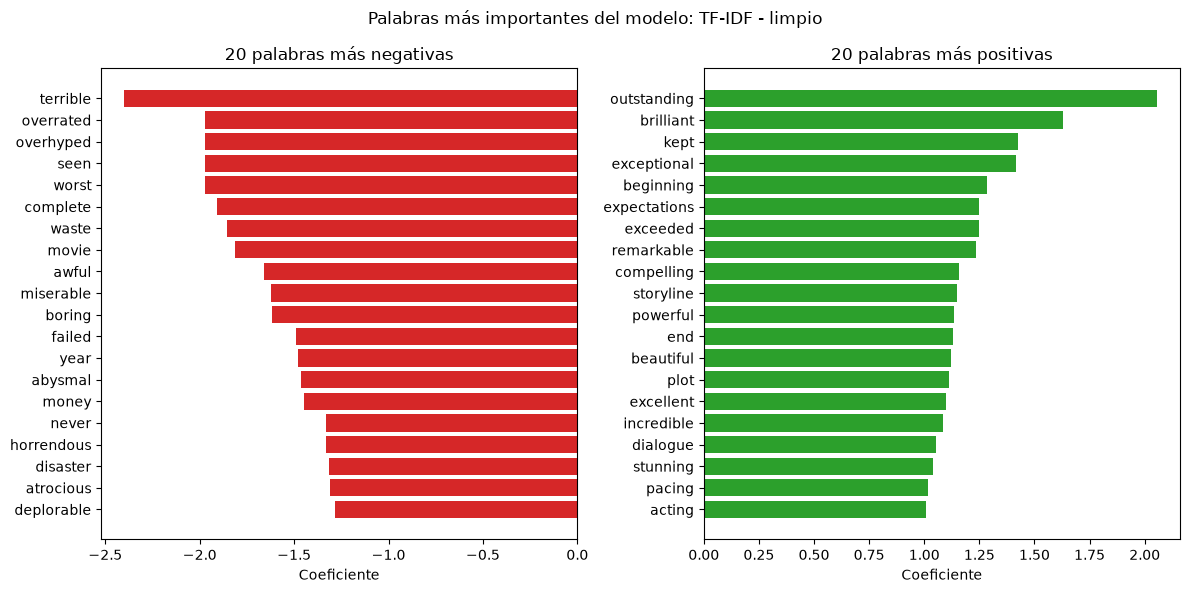

In [449]:
# TODO:
# Grafique las palabras positivas y negativas más importantes.

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].barh(top_neg["palabra"], top_neg["coeficiente"], color="tab:red")
axes[0].invert_yaxis()
axes[0].set_title("20 palabras más negativas")
axes[0].set_xlabel("Coeficiente")

axes[1].barh(top_pos["palabra"], top_pos["coeficiente"], color="tab:green")
axes[1].invert_yaxis()
axes[1].set_title("20 palabras más positivas")
axes[1].set_xlabel("Coeficiente")

fig.suptitle(f"Palabras más importantes del modelo: {best_experiment['experiment']}")
plt.tight_layout()
plt.show()

## Ejercicio 7

1. Revise las 20 palabras más positivas.

   **Respuesta:** La mitad son adjetivos de elogio: `outstanding`, `brilliant`, `exceptional`, `remarkable`, `compelling`, `powerful`, `beautiful`, `excellent`, `incredible`, `stunning`. El resto son aspectos de una película (`storyline`, `plot`, `dialogue`, `pacing`, `acting`) y palabras de frases típicas de las reseñas positivas, como `kept`, `beginning`, `end` o `exceeded expectations`.

2. Revise las 20 palabras más negativas.

   **Respuesta:** Predominan los adjetivos negativos: `terrible`, `overrated`, `overhyped`, `worst`, `awful`, `miserable`, `boring`, `abysmal`, `horrendous`, `atrocious`, `deplorable`. Junto a ellos están `waste`, `failed`, `disaster` y la negación `never`, que aparece porque la limpieza la conservó. Las que desentonan son `movie`, `seen`, `year`, `money` y `complete`.

3. ¿Todas tienen sentido semántico?

   **Respuesta:** La mayoría sí, pero no todas. Algunas pesan solo porque vienen de una frase que se repite: `seen` y `year` salen de *"Worst film I've seen this year"*, y `money` de *"waste of time and money"*. Y los aspectos como `plot` o `acting` cuentan como positivos por un efecto de las plantillas: las reseñas negativas no nombran ningún aspecto real (en su lugar tenían `{element}`), así que esas palabras solo aparecen en las positivas.

In [450]:
# Pregunta 3: palabras con mucho peso que por sí solas no expresan sentimiento
coef_mejor = coef_df.set_index("palabra")["coeficiente"]

for palabra in ["seen", "year", "money", "complete", "kept"]:
    idx = X_clean_train[X_clean_train.str.contains(rf"\b{palabra}\b")].index[0]
    print(f"{palabra} ({coef_mejor[palabra]:+.2f}): {df.loc[idx, TEXT_COL]}")

# Aspectos de una película: en cuántas reseñas de cada clase aparecen
texto_min = df[TEXT_COL].str.lower()
aspectos = pd.DataFrame({
    palabra: texto_min.str.contains(rf"\b{palabra}\b").groupby(df["sentiment_label"]).sum()
    for palabra in ["plot", "acting", "dialogue", "pacing", "storyline"]
})
display(aspectos)

seen (-1.97): Worst movie I've ever seen. Complete disaster. The {aspect} were insulting and the {element} was generic.
year (-1.48): Worst film I've seen this year. The {element} was boring and the {component} was unforgivable.
money (-1.45): Terrible movie, waste of time and money. The {aspect} was insulting and the {element} was derivative.
complete (-1.91): Worst movie I've ever seen. Complete disaster. The {aspect} were insulting and the {element} was generic.
kept (+1.42): Incredible editing and engaging pacing. The movie kept me on the edge of my seat throughout.


,plot,acting,dialogue,pacing,storyline
sentiment_label,,,,,
negative,0,0,0,0,0
positive,75,68,75,76,84


4. ¿Encuentra alguna palabra inesperada?

   **Respuesta:** Sí:

   - `movie` es de las más negativas (−1,81), aunque es una palabra neutra. Pasa porque en proporción aparece el doble en las reseñas negativas.
   - `plot`, `acting` y `dialogue` cuentan como positivas (alrededor de +1), cuando en una reseña real pueden ir con cualquier opinión.
   - `not` pesa muy poco (−0,35) frente a `never` (−1,33) o `no` (−1,24): el modelo no aprendió que invierte el sentido.

   Como contraste, en el modelo con texto original la palabra más influyente era `element` (−4,31), una plantilla que ni siquiera es parte real de una reseña. Con el texto limpio ese problema desaparece.

In [451]:
# Pregunta 4: palabras inesperadas en el mejor modelo, comparadas con el modelo de texto original
coef_original = pd.Series(tfidf_raw_result["model"].coef_[0],
                          index=tfidf_raw_result["vectorizer"].get_feature_names_out())

palabras = ["movie", "plot", "acting", "not", "no", "never", "element", "component", "aspect"]
display(pd.DataFrame({
    best_experiment["experiment"]: coef_mejor.reindex(palabras),
    "TF-IDF - original": coef_original.reindex(palabras),
}).round(2))

print("Más negativas con texto original:", coef_original.sort_values().head(5).index.tolist())
print("Más negativas con texto limpio:  ", coef_mejor.sort_values().head(5).index.tolist())

,TF-IDF - limpio,TF-IDF - original
movie,-1.81,-1.40
plot,1.11,0.94
acting,1.01,0.84
not,-0.35,-0.69
no,-1.24,-1.02
never,-1.33,-0.66
element,NaN,-4.31
component,NaN,-3.16
aspect,NaN,-2.45


Más negativas con texto original: ['element', 'component', 'aspect', 'complete', 'overhyped']
Más negativas con texto limpio:   ['terrible', 'overrated', 'overhyped', 'seen', 'worst']


5. ¿Qué nos dice esto sobre la interpretabilidad de modelos clásicos?

   **Respuesta:** Que son fáciles de revisar: basta mirar los coeficientes para saber en qué se fija el modelo. Aquí eso sirvió para comprobar que el modelo limpio se guía sobre todo por palabras de sentimiento, y para ver que el de texto original dependía de las plantillas, algo que el 100 % de accuracy no dejaba notar. El límite es que los coeficientes reflejan qué palabras coinciden con cada clase en estos datos, no lo que significan; por eso `movie` o `plot` terminan con peso. Hay que leerlos con criterio y no confiar solo en la métrica.

# 8. Análisis de errores

Las métricas agregadas son importantes, pero no son suficientes.

Un buen análisis de NLP debe revisar ejemplos concretos donde el modelo falla:

- Falsos positivos: reviews negativas clasificadas como positivas.
- Falsos negativos: reviews positivas clasificadas como negativas.
- Casos ambiguos.
- Textos con sarcasmo.
- Textos con negaciones.
- Textos demasiado cortos o demasiado largos.

Este análisis es clave para mejorar el pipeline.

In [452]:
# TODO:
# Construya un DataFrame con:
# - texto original
# - texto limpio
# - etiqueta real
# - predicción
# - probabilidad de clase positiva
# - tipo de error

print("Modelo analizado:", best_experiment["experiment"])

errors_df = pd.DataFrame({
    "texto_original": X_raw_test,
    "texto_limpio": X_clean_test,
    "etiqueta_real": y_test,
    "prediccion": best_experiment["y_pred"],
    "prob_positiva": best_experiment["y_proba"],
})

# Falso positivo: era negativa (0) y se predijo positiva (1). Falso negativo: lo contrario.
errors_df["tipo_error"] = np.select(
    [(errors_df["etiqueta_real"] == 0) & (errors_df["prediccion"] == 1),
     (errors_df["etiqueta_real"] == 1) & (errors_df["prediccion"] == 0)],
    ["Falso positivo", "Falso negativo"],
    default="Correcto",
)

print(errors_df["tipo_error"].value_counts().to_string())
errors_df.head()

Modelo analizado: TF-IDF - limpio
tipo_error
Correcto    239


,texto_original,texto_limpio,etiqueta_real,prediccion,prob_positiva,tipo_error
120,Miserable {component} and awful {element}. The movie was a farce from start to finish.,miserable awful movie farce start finish,0,0,0.219011,Correcto
191,Fantastic beginning and wonderful character development. The movie was a treasure that exceeded all expectations.,fantastic beginning wonderful character development movie treasure exceeded expectations,1,1,0.962233,Correcto
29,"Terrible movie, waste of time and money. The {aspect} was inappropriate and the {element} was inferior.",terrible movie waste time money inappropriate inferior,0,0,0.093795,Correcto
1407,"Complete disaster. The movie was overused, overused, and a complete waste of time.",complete disaster movie overused overused complete waste time,0,0,0.141734,Correcto
1404,Boring and predictable. Not worth watching. The movie offended me and the {element} was completely obvious.,boring predictable not worth watching movie offended completely obvious,0,0,0.146809,Correcto


In [453]:
# TODO:
# Muestre ejemplos de falsos positivos y falsos negativos.

for tipo in ["Falso positivo", "Falso negativo"]:
    tabla = errors_df[errors_df["tipo_error"] == tipo]
    print(f"{tipo.replace('Falso', 'Falsos')}s: {len(tabla)}")
    if tabla.empty:
        print("  No hay ninguno: el modelo acierta todas las reseñas de prueba.\n")
    for _, fila in tabla.head(5).iterrows():
        print(f"  [{fila['prob_positiva']:.2f}] {fila['texto_original']}")
        print(f"         limpio: {fila['texto_limpio']}\n")

Falsos positivos: 0
  No hay ninguno: el modelo acierta todas las reseñas de prueba.

Falsos negativos: 0
  No hay ninguno: el modelo acierta todas las reseñas de prueba.



,texto_original,texto_limpio,etiqueta_real,prediccion,prob_positiva
141,Miserable {component} and awful {element}. The movie was a mockery from start to finish.,miserable awful movie mockery start finish,0,0,0.234
1093,Dreadful {element} and appalling {aspect}. This movie is a mockery that should be avoided.,dreadful appalling movie mockery avoided,0,0,0.220
577,Dreadful {element} and appalling {aspect}. This movie is a joke that should be avoided.,dreadful appalling movie joke avoided,0,0,0.220
120,Miserable {component} and awful {element}. The movie was a farce from start to finish.,miserable awful movie farce start finish,0,0,0.219
1249,Dreadful {element} and appalling {aspect}. This movie is a turkey that should be avoided.,dreadful appalling movie turkey avoided,0,0,0.205
927,Dreadful {element} and appalling {aspect}. This movie is a catastrophe that should be avoided.,dreadful appalling movie catastrophe avoided,0,0,0.204
1376,Dreadful {element} and appalling {aspect}. This movie is a clunker that should be avoided.,dreadful appalling movie clunker avoided,0,0,0.204
764,Atrocious {element} and deplorable {aspect}. This is a joke that fails on every level.,atrocious deplorable joke fails level,0,0,0.202
275,Atrocious {element} and deplorable {aspect}. This is a mockery that fails on every level.,atrocious deplorable mockery fails level,0,0,0.202
146,Dreadful {element} and appalling {aspect}. This movie is a travesty that should be avoided.,dreadful appalling movie travesty avoided,0,0,0.195


Predicciones con probabilidad entre 0.2 y 0.8: 9 de 239
Confianza mínima: 0.766


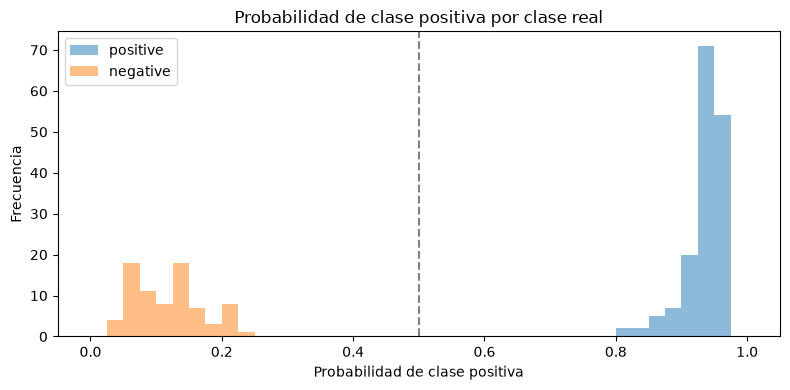

In [454]:
# TODO:
# Encuentre predicciones de baja confianza.
# Pista: probabilidad cercana a 0.5.

# Confianza: qué tan lejos está la probabilidad de 0.5 (0.5 = duda total, 1.0 = seguridad total)
errors_df["confianza"] = np.maximum(errors_df["prob_positiva"], 1 - errors_df["prob_positiva"])

baja_confianza = errors_df.sort_values("confianza").head(10)
display(baja_confianza[["texto_original", "texto_limpio", "etiqueta_real", "prediccion", "prob_positiva"]].round(3))

dudosas = errors_df["prob_positiva"].between(0.2, 0.8).sum()
print(f"Predicciones con probabilidad entre 0.2 y 0.8: {dudosas} de {len(errors_df)}")
print(f"Confianza mínima: {errors_df['confianza'].min():.3f}")

plt.figure(figsize=(8, 4))
for valor, nombre in [(1, "positive"), (0, "negative")]:
    plt.hist(errors_df.loc[errors_df["etiqueta_real"] == valor, "prob_positiva"],
             bins=np.linspace(0, 1, 41), alpha=0.5, label=nombre)
plt.axvline(0.5, color="gray", linestyle="--")
plt.title("Probabilidad de clase positiva por clase real")
plt.xlabel("Probabilidad de clase positiva")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

## 8.1 Análisis complementario: errores al entrenar con pocos datos

El mejor modelo acierta las 239 reseñas de prueba, así que no tiene falsos positivos ni falsos negativos que revisar. Para ver en qué tipo de reseñas falla dentro del mismo dataset, se repite el experimento de la sección 6.1: se entrena el mismo modelo (TF-IDF con texto limpio) con solo 40 reseñas, 30 veces, y se cuenta cuántas veces se equivoca en cada reseña de prueba.

In [455]:
# Errores del mejor tipo de modelo al entrenar con 40 reseñas, acumulados en 30 muestras
veces_fp = np.zeros(len(y_test), dtype=int)
veces_fn = np.zeros(len(y_test), dtype=int)

for semilla in range(N_MUESTRAS):
    idx = y_train.groupby(y_train).sample(N_POR_CLASE, random_state=semilla).index
    r = train_and_evaluate(TfidfVectorizer(max_features=5000),
                           X_clean_train.loc[idx], X_clean_test, y_train.loc[idx], y_test, "pocos datos")
    veces_fp += (r["y_pred"] == 1) & (y_test.values == 0)
    veces_fn += (r["y_pred"] == 0) & (y_test.values == 1)

stress_df = errors_df[["texto_original", "texto_limpio", "etiqueta_real"]].assign(veces_fp=veces_fp, veces_fn=veces_fn)

total = N_MUESTRAS * len(y_test)
print(f"Falsos positivos: {veces_fp.sum()} | Falsos negativos: {veces_fn.sum()} (de {total:,} predicciones)")
print(f"Reseñas distintas con algún error: {(veces_fp > 0).sum()} como falso positivo, {(veces_fn > 0).sum()} como falso negativo")

for titulo, columna in [("FALSOS POSITIVOS", "veces_fp"), ("FALSOS NEGATIVOS", "veces_fn")]:
    print(f"\n{titulo} más repetidos (veces que falló, de {N_MUESTRAS} modelos):")
    for _, fila in stress_df.sort_values(columna, ascending=False, kind="stable").head(5).iterrows():
        print(f"  [{fila[columna]}] {fila['texto_original']}")
        print(f"        limpio: {fila['texto_limpio']}")

Falsos positivos: 17 | Falsos negativos: 176 (de 7,170 predicciones)
Reseñas distintas con algún error: 7 como falso positivo, 29 como falso negativo

FALSOS POSITIVOS más repetidos (veces que falló, de 30 modelos):
  [4] Atrocious {element} and deplorable {aspect}. This is a joke that fails on every level.
        limpio: atrocious deplorable joke fails level
  [4] Atrocious {element} and deplorable {aspect}. This is a mockery that fails on every level.
        limpio: atrocious deplorable mockery fails level
  [3] Atrocious {element} and deplorable {aspect}. This is a turkey that fails on every level.
        limpio: atrocious deplorable turkey fails level
  [3] Atrocious {element} and deplorable {aspect}. This is a farce that fails on every level.
        limpio: atrocious deplorable farce fails level
  [1] Miserable {component} and awful {element}. The movie was a farce from start to finish.
        limpio: miserable awful movie farce start finish

FALSOS NEGATIVOS más repetidos (v

## 8.2 Prueba contrafactual: ¿qué pasa si las plantillas se rellenan?

En una reseña real, `{element}` sería una palabra concreta. Para comprobar si los modelos dependen de las plantillas, se toman las reseñas negativas de prueba que las tienen y se reemplaza cada `{…}` por una palabra neutra que ningún modelo conoce (`lighting`). El sentimiento de la reseña no cambia; si la predicción cambia, es que el modelo se apoyaba en la plantilla.

In [456]:
# Reseñas negativas de prueba con plantilla, antes y después de rellenarla
PALABRA_NEUTRA = "lighting"
assert all(PALABRA_NEUTRA not in r["vectorizer"].vocabulary_ for r in resultados), "la palabra debe ser desconocida"

con_plantilla = X_raw_test[(y_test == 0) & X_raw_test.str.contains(r"\{\w+\}")]
rellenadas = con_plantilla.str.replace(r"\{\w+\}", PALABRA_NEUTRA, regex=True)
print("Original: ", con_plantilla.iloc[0])
print("Rellenada:", rellenadas.iloc[0])

filas = []
for r in resultados:
    preparar = (lambda s: s.apply(clean_text)) if r["experiment"].endswith("limpio") else (lambda s: s)
    p_antes = r["model"].predict_proba(r["vectorizer"].transform(preparar(con_plantilla)))[:, 1]
    p_despues = r["model"].predict_proba(r["vectorizer"].transform(preparar(rellenadas)))[:, 1]
    filas.append({
        "experiment": r["experiment"],
        "reseñas": len(con_plantilla),
        "prob_positiva_antes": p_antes.mean(),
        "prob_positiva_despues": p_despues.mean(),
        "pasan_a_positiva": int((p_despues >= 0.5).sum()),
    })
contrafactual_df = pd.DataFrame(filas).set_index("experiment")
contrafactual_df.round(3)

Original:  Miserable {component} and awful {element}. The movie was a farce from start to finish.
Rellenada: Miserable lighting and awful lighting. The movie was a farce from start to finish.


,reseñas,prob_positiva_antes,prob_positiva_despues,pasan_a_positiva
experiment,,,,
Binary - original,70,0.013,0.222,6
Binary - limpio,70,0.026,0.026,0
BoW - original,70,0.013,0.256,19
BoW - limpio,70,0.027,0.027,0
TF-IDF - original,70,0.100,0.244,0
TF-IDF - limpio,70,0.116,0.116,0


## 8.3 Conjunto de desafío: negación, contraste, sarcasmo y vocabulario nuevo

La introducción de esta sección pide revisar textos con negaciones y sarcasmo, que el dataset casi no tiene. Para probarlos se escribieron a mano 16 reseñas cortas, cuatro por fenómeno. No es una muestra representativa ni sirve para medir el desempeño general: su único fin es ver cómo reacciona el modelo ante lenguaje que no vio.

In [457]:
# 16 reseñas escritas a mano: (texto, etiqueta real, fenómeno)
desafio = pd.DataFrame([
    ("I can't say anything bad about this film.", 1, "negación"),
    ("It never gets boring, not even for a minute.", 1, "negación"),
    ("The plot is not interesting and the acting is not convincing.", 0, "negación"),
    ("I would not recommend this movie to anyone.", 0, "negación"),
    ("The first half drags, but the final act is wonderful.", 1, "contraste"),
    ("It has a few weak scenes, yet overall it is a brilliant film.", 1, "contraste"),
    ("Lovely soundtrack and beautiful photography, but I was bored the whole time.", 0, "contraste"),
    ("It started as a masterpiece and ended as a disaster.", 0, "contraste"),
    ("Wonderful, exactly what I needed: a film that goes nowhere.", 0, "sarcasmo"),
    ("What a brilliant idea to make a movie with no plot at all.", 0, "sarcasmo"),
    ("Outstanding work, if the goal was to put the audience to sleep.", 0, "sarcasmo"),
    ("Sure, a masterpiece, just like every other forgettable sequel.", 0, "sarcasmo"),
    ("Hilarious, heartfelt and impossible to stop watching.", 1, "vocabulario nuevo"),
    ("A charming little comedy that made me smile all evening.", 1, "vocabulario nuevo"),
    ("Gripping from the opening scene, I enjoyed every second.", 1, "vocabulario nuevo"),
    ("Dull, lifeless and painfully slow.", 0, "vocabulario nuevo"),
], columns=["texto", "etiqueta_real", "fenomeno"])
desafio["texto_limpio"] = desafio["texto"].apply(clean_text)

# Accuracy de los seis modelos en el conjunto de desafío
filas = []
for r in resultados:
    textos = desafio["texto_limpio"] if r["experiment"].endswith("limpio") else desafio["texto"]
    pred = r["model"].predict(r["vectorizer"].transform(textos))
    filas.append({
        "experiment": r["experiment"],
        "aciertos": int((pred == desafio["etiqueta_real"]).sum()),
        "falsos_positivos": int(((pred == 1) & (desafio["etiqueta_real"] == 0)).sum()),
        "falsos_negativos": int(((pred == 0) & (desafio["etiqueta_real"] == 1)).sum()),
    })
display(pd.DataFrame(filas).set_index("experiment"))

# Detalle con el mejor modelo
X_desafio = best_experiment["vectorizer"].transform(desafio["texto_limpio"])
desafio["prob_positiva"] = best_experiment["model"].predict_proba(X_desafio)[:, 1]
desafio["prediccion"] = (desafio["prob_positiva"] >= 0.5).astype(int)
desafio["palabras_reconocidas"] = np.asarray((X_desafio > 0).sum(axis=1)).ravel()
desafio["resultado"] = np.select(
    [(desafio["etiqueta_real"] == 0) & (desafio["prediccion"] == 1),
     (desafio["etiqueta_real"] == 1) & (desafio["prediccion"] == 0)],
    ["Falso positivo", "Falso negativo"], default="Correcto")

print("Mejor modelo:", best_experiment["experiment"])
display(pd.crosstab(desafio["fenomeno"], desafio["resultado"]))
display(desafio[["texto", "fenomeno", "etiqueta_real", "prob_positiva", "palabras_reconocidas", "resultado"]].round(3))

,aciertos,falsos_positivos,falsos_negativos
experiment,,,
Binary - original,7,9,0
Binary - limpio,6,8,2
BoW - original,7,9,0
BoW - limpio,6,8,2
TF-IDF - original,7,9,0
TF-IDF - limpio,5,8,3


Mejor modelo: TF-IDF - limpio


resultado,Correcto,Falso negativo,Falso positivo
fenomeno,,,
contraste,2,0,2
negación,1,2,1
sarcasmo,0,0,4
vocabulario nuevo,2,1,1


,texto,fenomeno,etiqueta_real,prob_positiva,palabras_reconocidas,resultado
0,I can't say anything bad about this film.,negación,1,0.462,3,Falso negativo
1,"It never gets boring, not even for a minute.",negación,1,0.378,4,Falso negativo
2,The plot is not interesting and the acting is not convincing.,negación,0,0.761,3,Falso positivo
3,I would not recommend this movie to anyone.,negación,0,0.456,2,Correcto
4,"The first half drags, but the final act is wonderful.",contraste,1,0.847,1,Correcto
5,"It has a few weak scenes, yet overall it is a brilliant film.",contraste,1,0.716,3,Correcto
6,"Lovely soundtrack and beautiful photography, but I was bored the whole time.",contraste,0,0.749,4,Falso positivo
7,It started as a masterpiece and ended as a disaster.,contraste,0,0.623,2,Falso positivo
8,"Wonderful, exactly what I needed: a film that goes nowhere.",sarcasmo,0,0.760,2,Falso positivo
9,What a brilliant idea to make a movie with no plot at all.,sarcasmo,0,0.695,4,Falso positivo


## Ejercicio 8

1. Revise 5 falsos positivos.

   **Respuesta:** En el conjunto de prueba el mejor modelo no tiene ninguno. Los que revisé salen del conjunto de desafío (sección 8.3), donde clasifica como positivas 8 de las 9 reseñas negativas. Cinco de ellas:

   - *"Sure, a masterpiece, just like every other forgettable sequel."* (0,85, sarcasmo)
   - *"Outstanding work, if the goal was to put the audience to sleep."* (0,78, sarcasmo)
   - *"Wonderful, exactly what I needed: a film that goes nowhere."* (0,76, sarcasmo)
   - *"The plot is not interesting and the acting is not convincing."* (0,76, negación)
   - *"Lovely soundtrack and beautiful photography, but I was bored the whole time."* (0,75, contraste)

2. Revise 5 falsos negativos.

   **Respuesta:** Tampoco hay en el conjunto de prueba. Tres salen del conjunto de desafío y dos del experimento con pocos datos (sección 8.1):

   - *"It never gets boring, not even for a minute."* (0,38, negación)
   - *"I can't say anything bad about this film."* (0,46, negación)
   - *"Hilarious, heartfelt and impossible to stop watching."* (0,50, vocabulario nuevo)
   - *"This is why I love art… I didn't want it to end."* (falla en 19 de 30 modelos)
   - *"Beautiful soundtrack and powerful executions. This movie will stay with me for a long time."* (falla en 11 de 30)

3. ¿Qué patrones encuentra?

   **Respuesta:**

   - **Sarcasmo:** falla las cuatro. Ve `masterpiece`, `outstanding` o `wonderful` y no puede saber que se dicen con ironía.
   - **Negación:** `not` casi no pesa, así que *"not interesting"* apenas resta y la frase se decide por `plot` y `acting`, que el modelo aprendió como positivas. Al revés, `never`, `bad` y `boring` empujan a negativo aunque la frase esté negando algo malo.
   - **Contraste:** el modelo solo suma los pesos de las palabras que conoce, sin tener en cuenta que lo que viene después del `but` es lo que decide la opinión.
   - **Palabras que no conoce:** si reconoce una o ninguna, responde cerca de 0,5 o se va a positivo, porque en el entrenamiento había más reseñas positivas. *"Dull, lifeless and painfully slow"* sale positiva sin que reconozca ni una palabra.

4. ¿Los errores parecen deberse a limpieza, representación o ambigüedad del lenguaje?

   **Respuesta:** Sobre todo a la representación: al tratar cada palabra por separado y sin orden, el modelo no puede captar la negación ni el contraste, y una palabra que no vio no le aporta nada. En el sarcasmo la causa es la ambigüedad del lenguaje: ni con todas las palabras conocidas se podría resolver sin entender la intención. La limpieza no es la causa principal, aunque con pocos datos sí quita pistas: la frase *"…will stay with me for a long time"* falla 69 veces de 240 con texto limpio y ninguna con el original, porque stop words como `me` o `will` ayudaban a reconocerla.

In [458]:
# Pregunta 4: errores con pocos datos en dos frases positivas, con texto limpio y con texto original
frases = {
    "... I didn't want it to end": X_raw_test.str.contains("want it to end").values,
    "... will stay with me for a long time": X_raw_test.str.contains("stay with me").values,
}

filas = []
for nombre_txt, X_tr, X_te in [("limpio", X_clean_train, X_clean_test), ("original", X_raw_train, X_raw_test)]:
    errores = np.zeros(len(y_test), dtype=int)
    for semilla in range(N_MUESTRAS):
        idx = y_train.groupby(y_train).sample(N_POR_CLASE, random_state=semilla).index
        r = train_and_evaluate(TfidfVectorizer(max_features=5000), X_tr.loc[idx], X_te, y_train.loc[idx], y_test, "pocos datos")
        errores += r["y_pred"] != y_test.values
    for frase, mascara in frases.items():
        filas.append({"frase": frase, "texto": nombre_txt, "errores": errores[mascara].sum()})

tabla = pd.DataFrame(filas).pivot(index="frase", columns="texto", values="errores")[["limpio", "original"]]
tabla["predicciones"] = [frases[f].sum() * N_MUESTRAS for f in tabla.index]
tabla

texto,limpio,original,predicciones
frase,,,
... I didn't want it to end,57,2,120
... will stay with me for a long time,69,0,240


5. Proponga una mejora al pipeline.

   **Respuesta:** Primero probé dos cambios sencillos: agregar bigramas y quitar `movie` y `film` como stop words del dominio. Ninguno resuelve el problema. Con reseñas reales los bigramas no mejoran (ROC-AUC de 0,760 contra 0,766) y quitar `movie` y `film` ayuda un poco (0,782); en el conjunto de desafío siguen acertando apenas 6 y 4 de 16.

   La mejora que propongo es otra: entrenar con reseñas reales. El modelo falla porque aprendió de frases artificiales, no por la representación, y con datos reales los bigramas sí tendrían negaciones de las que aprender. Para el sarcasmo y el contraste haría falta además un modelo que entienda el contexto, como embeddings o un transformer.

In [459]:
# Pregunta 5: dos mejoras sencillas, medidas de tres formas (texto limpio)
variantes = {
    "TF-IDF (actual)": lambda: TfidfVectorizer(max_features=5000),
    "TF-IDF + bigramas": lambda: TfidfVectorizer(max_features=5000, ngram_range=(1, 2)),
    "TF-IDF sin 'movie' ni 'film'": lambda: TfidfVectorizer(max_features=5000, stop_words=["movie", "film"]),
}

filas = []
for nombre, crear in variantes.items():
    # a) F1 medio al entrenar con 40 reseñas
    f1_pocos = []
    for semilla in range(N_MUESTRAS):
        idx = y_train.groupby(y_train).sample(N_POR_CLASE, random_state=semilla).index
        f1_pocos.append(train_and_evaluate(crear(), X_clean_train.loc[idx], X_clean_test,
                                           y_train.loc[idx], y_test, nombre)["f1"])
    # b) y c) Modelo entrenado con todo el train, evaluado en reseñas reales y en el conjunto de desafío
    vec = crear()
    modelo = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(vec.fit_transform(X_clean_train), y_train)
    proba_real = modelo.predict_proba(vec.transform(real["review_clean"]))[:, 1]
    aciertos = int((modelo.predict(vec.transform(desafio["texto_limpio"])) == desafio["etiqueta_real"]).sum())
    filas.append({"variante": nombre, "f1_40_reseñas": np.mean(f1_pocos),
                  "roc_auc_real": roc_auc_score(real["y"], proba_real), "aciertos_desafio (de 16)": aciertos})
pd.DataFrame(filas).set_index("variante").round(3)

,f1_40_reseñas,roc_auc_real,aciertos_desafio (de 16)
variante,,,
TF-IDF (actual),0.980,0.766,5
TF-IDF + bigramas,0.982,0.760,6
TF-IDF sin 'movie' ni 'film',0.983,0.782,4


# 9. Conclusiones y próximos pasos

En este notebook construimos un pipeline completo de análisis de sentimiento usando técnicas clásicas de NLP.

## Lo aprendido

1. La exploración textual permite entender longitud, vocabulario, ruido y diferencias entre clases.
2. La limpieza textual puede ayudar, pero también puede eliminar información útil.
3. Binary Encoding representa presencia/ausencia de palabras.
4. Bag of Words conserva frecuencia.
5. TF-IDF pondera la importancia relativa de cada palabra.
6. Logistic Regression es un modelo fuerte, simple e interpretable para clasificación de texto clásica.
7. Las métricas deben complementarse con análisis de errores.
8. La interpretación de coeficientes ayuda a entender qué aprendió el modelo.

## Limitaciones de los métodos clásicos

Estos métodos no capturan bien:

- Orden de palabras.
- Sarcasmo.
- Contexto largo.
- Significado profundo.
- Relaciones semánticas.
- Ambigüedad lingüística.

## Próximos pasos recomendados

Para continuar la clase o el proyecto, se puede explorar:

- N-gramas.
- Comparación entre stop words con y sin negaciones.
- Lemmatization con spaCy.
- Word embeddings.
- Modelos basados en transformers.
- Fine-tuning de BERT para análisis de sentimiento.

## Ejercicio final

Construya una conclusión ejecutiva de máximo 10 líneas respondiendo:

1. ¿Cuál fue el mejor modelo?
2. ¿Qué representación textual funcionó mejor?
3. ¿La limpieza ayudó?
4. ¿Qué limitaciones observó?
5. ¿Qué recomendaría como siguiente experimento?

**Conclusión ejecutiva:**

1. **Mejor modelo:** Logistic Regression con TF-IDF sobre texto limpio. Los seis experimentos llegan a 1,0 en el conjunto de prueba, así que lo elegí por ser el mejor con reseñas reales (ROC-AUC de 0,766).
2. **Representación:** en el conjunto de prueba, Binary, BoW y TF-IDF empatan. Con reseñas reales gana TF-IDF (0,766), seguido de Binary (0,749) y BoW (0,702).
3. **Limpieza:** no cambió las métricas de prueba, pero sí ayudó: eliminó las plantillas `{element}`, presentes en el 95 % de las reseñas negativas, y mejoró las tres representaciones con reseñas reales.
4. **Limitaciones:** el dataset es sintético (40 % de duplicados, plantillas y vocabularios casi separados), así que el 100 % no es real: con reseñas reales el mejor modelo acierta el 66 %, y con negaciones y sarcasmo, 5 de 16.
5. **Siguiente experimento:** entrenar con reseñas reales usando bigramas y comparar contra una representación con embeddings.

# Anexo opcional: ideas para extender el notebook

Si se desea convertir este notebook en una práctica más avanzada, se pueden agregar:

1. `ngram_range=(1,2)` para incluir bigramas como `not good`.
2. Comparación entre remover y conservar negaciones.
3. Validación cruzada.
4. Búsqueda de hiperparámetros con `GridSearchCV`.
5. Exportación del mejor modelo con `joblib`.
6. Construcción de una función `predict_sentiment(text)`.

## A.1 Bigramas con `ngram_range=(1, 2)`

Se entrena el mejor modelo agregando bigramas. El F1 sigue en 1,0, pero el vocabulario pasa de 300 a 2.204 features. Lo interesante está en los coeficientes: el modelo ahora distingue `not worth` (negativo) de `not want` (positivo, de *"did not want it to end"*), algo que con la palabra `not` suelta no podía hacer.

In [460]:
# A.1 TF-IDF con unigramas y bigramas sobre texto limpio
bigram_result = train_and_evaluate(
    TfidfVectorizer(max_features=5000, ngram_range=(1, 2)),
    X_clean_train, X_clean_test, y_train, y_test,
    "TF-IDF - limpio + bigramas",
)
print(f"F1: {bigram_result['f1']:.3f} | features: {bigram_result['n_features']} (sin bigramas: {best_experiment['n_features']})")

# Coeficientes de las negaciones, solas y dentro de bigramas
coef_bigramas = pd.Series(bigram_result["model"].coef_[0],
                          index=bigram_result["vectorizer"].get_feature_names_out())
es_negacion = coef_bigramas.index.str.match(r"^(?:not|no|never)(?: |$)")
coef_bigramas[es_negacion].sort_values().round(2)

F1: 1.000 | features: 2204 (sin bigramas: 300)


never       -1.18
no          -1.14
no sense    -1.14
not worth   -0.62
not         -0.37
not want     0.25
dtype: float64

## A.2 Remover o conservar negaciones

Se compara el texto limpio actual, que conserva `not`, `no` y `never`, con una versión que también las elimina. En este dataset no cambia nada: los dos llegan a F1 de 1,0, y con 40 reseñas quedan en 0,980 y 0,982. Solo 82 reseñas tienen negaciones y sus otras palabras ya bastan para clasificarlas. Con lenguaje real sí importan, como muestra el conjunto de desafío de la sección 8.3.

In [461]:
# A.2 Mismo modelo con y sin negaciones en el texto limpio
def quitar_negaciones(textos):
    return textos.apply(lambda t: " ".join(w for w in t.split() if w not in ENGLISH_STOP_WORDS))

X_sin_neg_train, X_sin_neg_test = quitar_negaciones(X_clean_train), quitar_negaciones(X_clean_test)

filas = []
for nombre, X_tr, X_te in [("Conserva negaciones", X_clean_train, X_clean_test),
                           ("Remueve negaciones", X_sin_neg_train, X_sin_neg_test)]:
    completo = train_and_evaluate(TfidfVectorizer(max_features=5000), X_tr, X_te, y_train, y_test, nombre)
    f1_pocos = []
    for semilla in range(N_MUESTRAS):
        idx = y_train.groupby(y_train).sample(N_POR_CLASE, random_state=semilla).index
        f1_pocos.append(train_and_evaluate(TfidfVectorizer(max_features=5000),
                                           X_tr.loc[idx], X_te, y_train.loc[idx], y_test, nombre)["f1"])
    filas.append({"texto": nombre, "f1": completo["f1"], "n_features": completo["n_features"],
                  "f1_40_reseñas": np.mean(f1_pocos)})
pd.DataFrame(filas).set_index("texto").round(3)

,f1,n_features,f1_40_reseñas
texto,,,
Conserva negaciones,1.0,300,0.980
Remueve negaciones,1.0,296,0.982


## A.3 Validación cruzada

En lugar de una sola división, el conjunto de entrenamiento se parte en 5 y el modelo se evalúa 5 veces, cada vez con una parte distinta como validación. El vectorizador va dentro de un `Pipeline` para que aprenda el vocabulario solo con los datos de entrenamiento de cada partición. El F1 medio es 0,999 (cuatro particiones en 1,0 y una en 0,996), lo que confirma que el resultado no fue suerte de la división original.

In [462]:
# A.3 Validación cruzada estratificada de 5 particiones sobre el conjunto de entrenamiento
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000)),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for metrica in ["accuracy", "f1", "roc_auc"]:
    scores = cross_val_score(pipeline, X_clean_train, y_train, cv=cv, scoring=metrica)
    print(f"{metrica:9}: {scores.round(3)} | media = {scores.mean():.3f}")

accuracy : [1.    0.995 1.    1.    1.   ] | media = 0.999
f1       : [1.    0.996 1.    1.    1.   ] | media = 0.999
roc_auc  : [1. 1. 1. 1. 1.] | media = 1.000


## A.4 Búsqueda de hiperparámetros con `GridSearchCV`

Se prueban 8 combinaciones: con y sin bigramas, y cuatro valores de `C` (la regularización de Logistic Regression). Aquí sí hay diferencias: con `C` muy bajo (0,01) el modelo queda tan restringido que casi siempre predice la clase mayoritaria y el F1 cae a 0,81. La mejor combinación es `C=10` sin bigramas, con F1 de 1,0 y el menor log loss (0,020).

In [463]:
# A.4 GridSearchCV sobre el pipeline, con F1 y log loss como métricas
param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "clf__C": [0.01, 0.1, 1, 10],
}
grid = GridSearchCV(pipeline, param_grid, cv=cv,
                    scoring={"f1": "f1", "log_loss": "neg_log_loss"}, refit="log_loss")
grid.fit(X_clean_train, y_train)

cv_df = pd.DataFrame(grid.cv_results_)[["param_tfidf__ngram_range", "param_clf__C", "mean_test_f1", "mean_test_log_loss"]]
cv_df["mean_test_log_loss"] = -cv_df["mean_test_log_loss"]  # scikit-learn lo guarda con signo negativo
display(cv_df.sort_values("mean_test_log_loss").round(4))

print("Mejor combinación según log loss:", grid.best_params_)
print(f"F1 en prueba con esa combinación: {f1_score(y_test, grid.predict(X_clean_test)):.3f}")

,param_tfidf__ngram_range,param_clf__C,mean_test_f1,mean_test_log_loss
6,"(1, 1)",10.00,1.0000,0.0201
7,"(1, 2)",10.00,0.9992,0.0230
4,"(1, 1)",1.00,0.9992,0.1051
5,"(1, 2)",1.00,0.9992,0.1262
2,"(1, 1)",0.10,0.9470,0.3634
3,"(1, 2)",0.10,0.8993,0.4178
0,"(1, 1)",0.01,0.8055,0.5837
1,"(1, 2)",0.01,0.8055,0.5994


Mejor combinación según log loss: {'clf__C': 10, 'tfidf__ngram_range': (1, 1)}
F1 en prueba con esa combinación: 1.000


## A.5 Exportación del mejor modelo con `joblib`

Se guarda en un archivo el pipeline completo (vectorizador y modelo) del mejor experimento, para poder usarlo después sin volver a entrenar. Se comprueba que el modelo cargado da las mismas predicciones. El archivo espera texto ya limpio: quien lo use debe aplicar antes `clean_text`.

In [464]:
# A.5 Guardar y volver a cargar el mejor modelo (TF-IDF con texto limpio)
import joblib

final_model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000)),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
]).fit(X_clean_train, y_train)

MODEL_PATH = "sentiment_model.joblib"
joblib.dump(final_model, MODEL_PATH)
print(f"Modelo guardado en {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1024:.1f} KB)")

modelo_cargado = joblib.load(MODEL_PATH)
iguales = (modelo_cargado.predict(X_clean_test) == best_experiment["y_pred"]).all()
print("¿El modelo cargado predice igual que el mejor experimento?", iguales)

Modelo guardado en sentiment_model.joblib (14.9 KB)
¿El modelo cargado predice igual que el mejor experimento? True


## A.6 Función `predict_sentiment(text)`

La función limpia el texto, lo vectoriza con el mejor modelo y devuelve el sentimiento con su probabilidad. También informa cuántas palabras del texto reconoce el modelo, porque ahí está su límite: acierta con reseñas parecidas a las del dataset, pero con frases escritas de otra forma reconoce pocas palabras y casi adivina. *"I loved it, one of the best films of the year!"* queda en 0,51, prácticamente un empate, y *"It was fine"* no tiene ninguna palabra conocida: sale positiva (0,68) solo porque en el entrenamiento había más reseñas positivas.

In [465]:
# TODO OPCIONAL:
# Construya una función predict_sentiment(text) usando el mejor modelo.

def predict_sentiment(text):
    texto_limpio = clean_text(text)
    X = best_experiment["vectorizer"].transform([texto_limpio])
    prob_positiva = best_experiment["model"].predict_proba(X)[0, 1]
    return {
        "sentimiento": "positive" if prob_positiva >= 0.5 else "negative",
        "prob_positiva": round(float(prob_positiva), 3),
        "palabras_reconocidas": int(X.nnz),  # palabras del texto que están en el vocabulario del modelo
        "texto_limpio": texto_limpio,
    }

ejemplos = [
    "Brilliant screenplay and outstanding acting. A true masterpiece.",
    "Terrible plot and awful dialogue. A complete waste of time.",
    "This movie was not good at all.",
    "I loved it, one of the best films of the year!",
    "It was fine.",
]
pd.DataFrame([predict_sentiment(t) for t in ejemplos], index=ejemplos)

,sentimiento,prob_positiva,palabras_reconocidas,texto_limpio
Brilliant screenplay and outstanding acting. A true masterpiece.,positive,0.965,5,brilliant screenplay outstanding acting true masterpiece
Terrible plot and awful dialogue. A complete waste of time.,negative,0.140,7,terrible plot awful dialogue complete waste time
This movie was not good at all.,negative,0.456,2,movie not good
"I loved it, one of the best films of the year!",positive,0.505,2,loved best films year
It was fine.,positive,0.679,0,fine
